# Lab 2 - Bài Tập Nâng Cao: Khám Phá & Mô Hình Hóa Chuỗi Thời Gian Airline Passengers
## Tích Hợp Toàn Diện: EDA Chuyên Sâu (Phần 1) & Mô Hình Hóa Mùa Vụ Với SARIMA (Phần 2)

**Cấu trúc bài thực hành gồm 2 phần:**
- **PHẦN 1: KHÁM PHÁ & PHÂN TÍCH CHUỖI THỜI GIAN (EDA)**
  1. Tải dữ liệu, chuẩn hóa DatetimeIndex & kiểm tra tính toàn vẹn thời gian (`asfreq('MS')`).
  2. Trực quan hóa chuỗi gốc + Rolling Mean (12m) + Dải biến động ±2σ + Mean tổng thể + Cực trị Min/Max.
  3. Phân rã chuỗi thời gian: STL (Loess) & Mô hình Nhân (Multiplicative Decomposition).
  4. Khảo sát Lược đồ ACF của 2 thành phần phần dư (STL vs Multiplicative).
  5. Boxplot đa chiều theo Tháng (Mùa vụ s=12) & theo Năm (Xu hướng & Phương sai).
  6. Lược đồ ACF sơ bộ chuỗi gốc.
- **PHẦN 2: BÀI TẬP NÂNG CAO - MÔ HÌNH HÓA MÙA VỤ VỚI SARIMA (7 BƯỚC CHUẨN MỰC)**
  - Bước 1: Trực quan hóa chuỗi thời gian & Nhận diện mùa vụ (s = 12).
  - Bước 2: Kiểm định nghiệm đơn vị (ADF Test) trên chuỗi gốc.
  - Bước 3: Sai phân thường (d=1) kết hợp Sai phân mùa vụ (D=1, s=12) & Kiểm định ADF từng giai đoạn.
  - Bước 4: Khảo sát Lược đồ ACF & PACF trên chuỗi sai phân kép xác định (p, q, P, Q).
  - Bước 5: Phân chia Train 80% / Test 20% & Huấn luyện (Fit) mô hình SARIMA và mô hình đối chuẩn ARIMA.
  - Bước 6: Dự báo ngoài mẫu (Out-of-sample Forecast) & Đánh giá sai số (MAE, RMSE, MAPE).
  - Bước 7: So sánh trực diện hiệu quả mô hình (Bảng đối sánh số liệu & Đồ thị dự báo ngoài mẫu).


In [8]:
# 1. Khai báo các thư viện cần thiết cho khám phá chuỗi thời gian
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.tsa.seasonal import STL, seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf
from IPython.display import display

# Cấu hình thẩm mỹ đồ thị khoa học
sns.set_theme(style='whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.unicode_minus'] = False


## 1. Tải Dữ Liệu & Kiểm Tra Cấu Trúc Toàn Vẹn
### Phương pháp kiểm chứng dữ liệu:
- **Tải và phân tích cú pháp thời gian (`parse_dates`):** Đọc chuỗi thời gian từ CSV, chuyển cột `Month` thành kiểu dữ liệu chuẩn `datetime` và gán làm Index.
- **Chuẩn hóa tần suất thời gian (`asfreq('MS')`):** Thiết lập chuỗi thời gian ở tần suất bắt đầu mỗi tháng (`Month-Start`). Việc này giúp đảm bảo dữ liệu có tính chu kỳ cố định, đồng thời tự động phát hiện nếu có tháng nào bị khuyết thiếu (missing timestamp).
- **Kiểm tra thông số thống kê (`head`, `info`, `describe`, `isnull`):** Đánh giá kích thước mẫu, kiểu dữ liệu, các giá trị ngoại lệ (min, max, phân vị), và xác nhận không có giá trị rỗng (`NaN`).


In [9]:
# 1. Tải dữ liệu airline-passengers.csv và chuẩn hóa DatetimeIndex
file_path = '../data/raw/airline-passengers.csv' if os.path.exists('../data/raw/airline-passengers.csv') else 'data/raw/airline-passengers.csv'
df = pd.read_csv(file_path, parse_dates=['Month'], index_col='Month')
df.index.name = 'Date'
df = df.asfreq('MS')

print("=" * 65)
print(f"Khoảng thời gian: {df.index.min().strftime('%Y-%m')} đến {df.index.max().strftime('%Y-%m')}")
print(f"Tổng số mốc quan sát (tháng): {len(df)}")
print(f"Số lượng giá trị khuyết thiếu (Missing/NaN): {df['Passengers'].isnull().sum()}")
print("=" * 65)

display(df.head(10))
display(df.info())
display(df.describe())


Khoảng thời gian: 1949-01 đến 1960-12
Tổng số mốc quan sát (tháng): 144
Số lượng giá trị khuyết thiếu (Missing/NaN): 0


,Passengers
Date,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121
1949-06-01,135
1949-07-01,148
1949-08-01,148
1949-09-01,136


<class 'pandas.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Freq: MS
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB


None

,Passengers
count,144.000000
mean,280.298611
std,119.966317
min,104.000000
25%,180.000000
50%,265.500000
75%,360.500000
max,622.000000


## 2. Trực Quan Hóa Chuỗi Thời Gian & Thống Kê Trượt (Rolling Statistics)
### 📌 Phương pháp kiểm chứng dữ liệu:
- **Biểu đồ chuỗi gốc (Time Series Plot):** Cho cái nhìn trực quan về hình thái tổng thể của chuỗi qua 12 năm (1949 - 1960).
- **Trung bình trượt (Rolling Mean 12 tháng):** Cửa sổ trượt đúng bằng chu kỳ năm ($w=12$) giúp triệt tiêu dao động mùa vụ trong năm, làm nổi bật đường **Xu hướng dài hạn (Long-term Trend)**.
- **Độ lệch chuẩn trượt (Rolling Std 12 tháng) & Dải biến động $\pm 2\sigma$:** Giúp kiểm chứng tính **Đồng nhất phương sai (Homoscedasticity)** hay **Phương sai thay đổi (Heteroscedasticity)**:
  - Nếu dải $\pm 2\sigma$ có bề rộng không đổi qua các năm $\rightarrow$ Phương sai không đổi (Additive).
  - Nếu dải $\pm 2\sigma$ mở rộng dần khi giá trị chuỗi tăng cao $\rightarrow$ Phương sai tăng dần theo thời gian (Multiplicative) $\implies$ Cần can thiệp biến đổi Logarit hoặc Box-Cox.
- **Đường Mean tổng thể (Overall Mean):** Đánh giá mức kỳ vọng toàn chuỗi $\mu = 280.30$ nghìn khách.
- **Điểm cực trị MIN & MAX:**
  - **MIN:** **104 nghìn khách** vào **tháng 11/1949** (Mùa đông thấp điểm nhất lịch sử 12 năm).
  - **MAX:** **622 nghìn khách** vào **tháng 07/1960** (Mùa hè cao điểm du lịch bùng nổ nhất).


Mean tổng thể: 280.30 nghìn khách
MIN: 104 nghìn khách tại thời điểm 1949-11 (Tháng 11/1949)
MAX: 622 nghìn khách tại thời điểm 1960-07 (Tháng 07/1960)


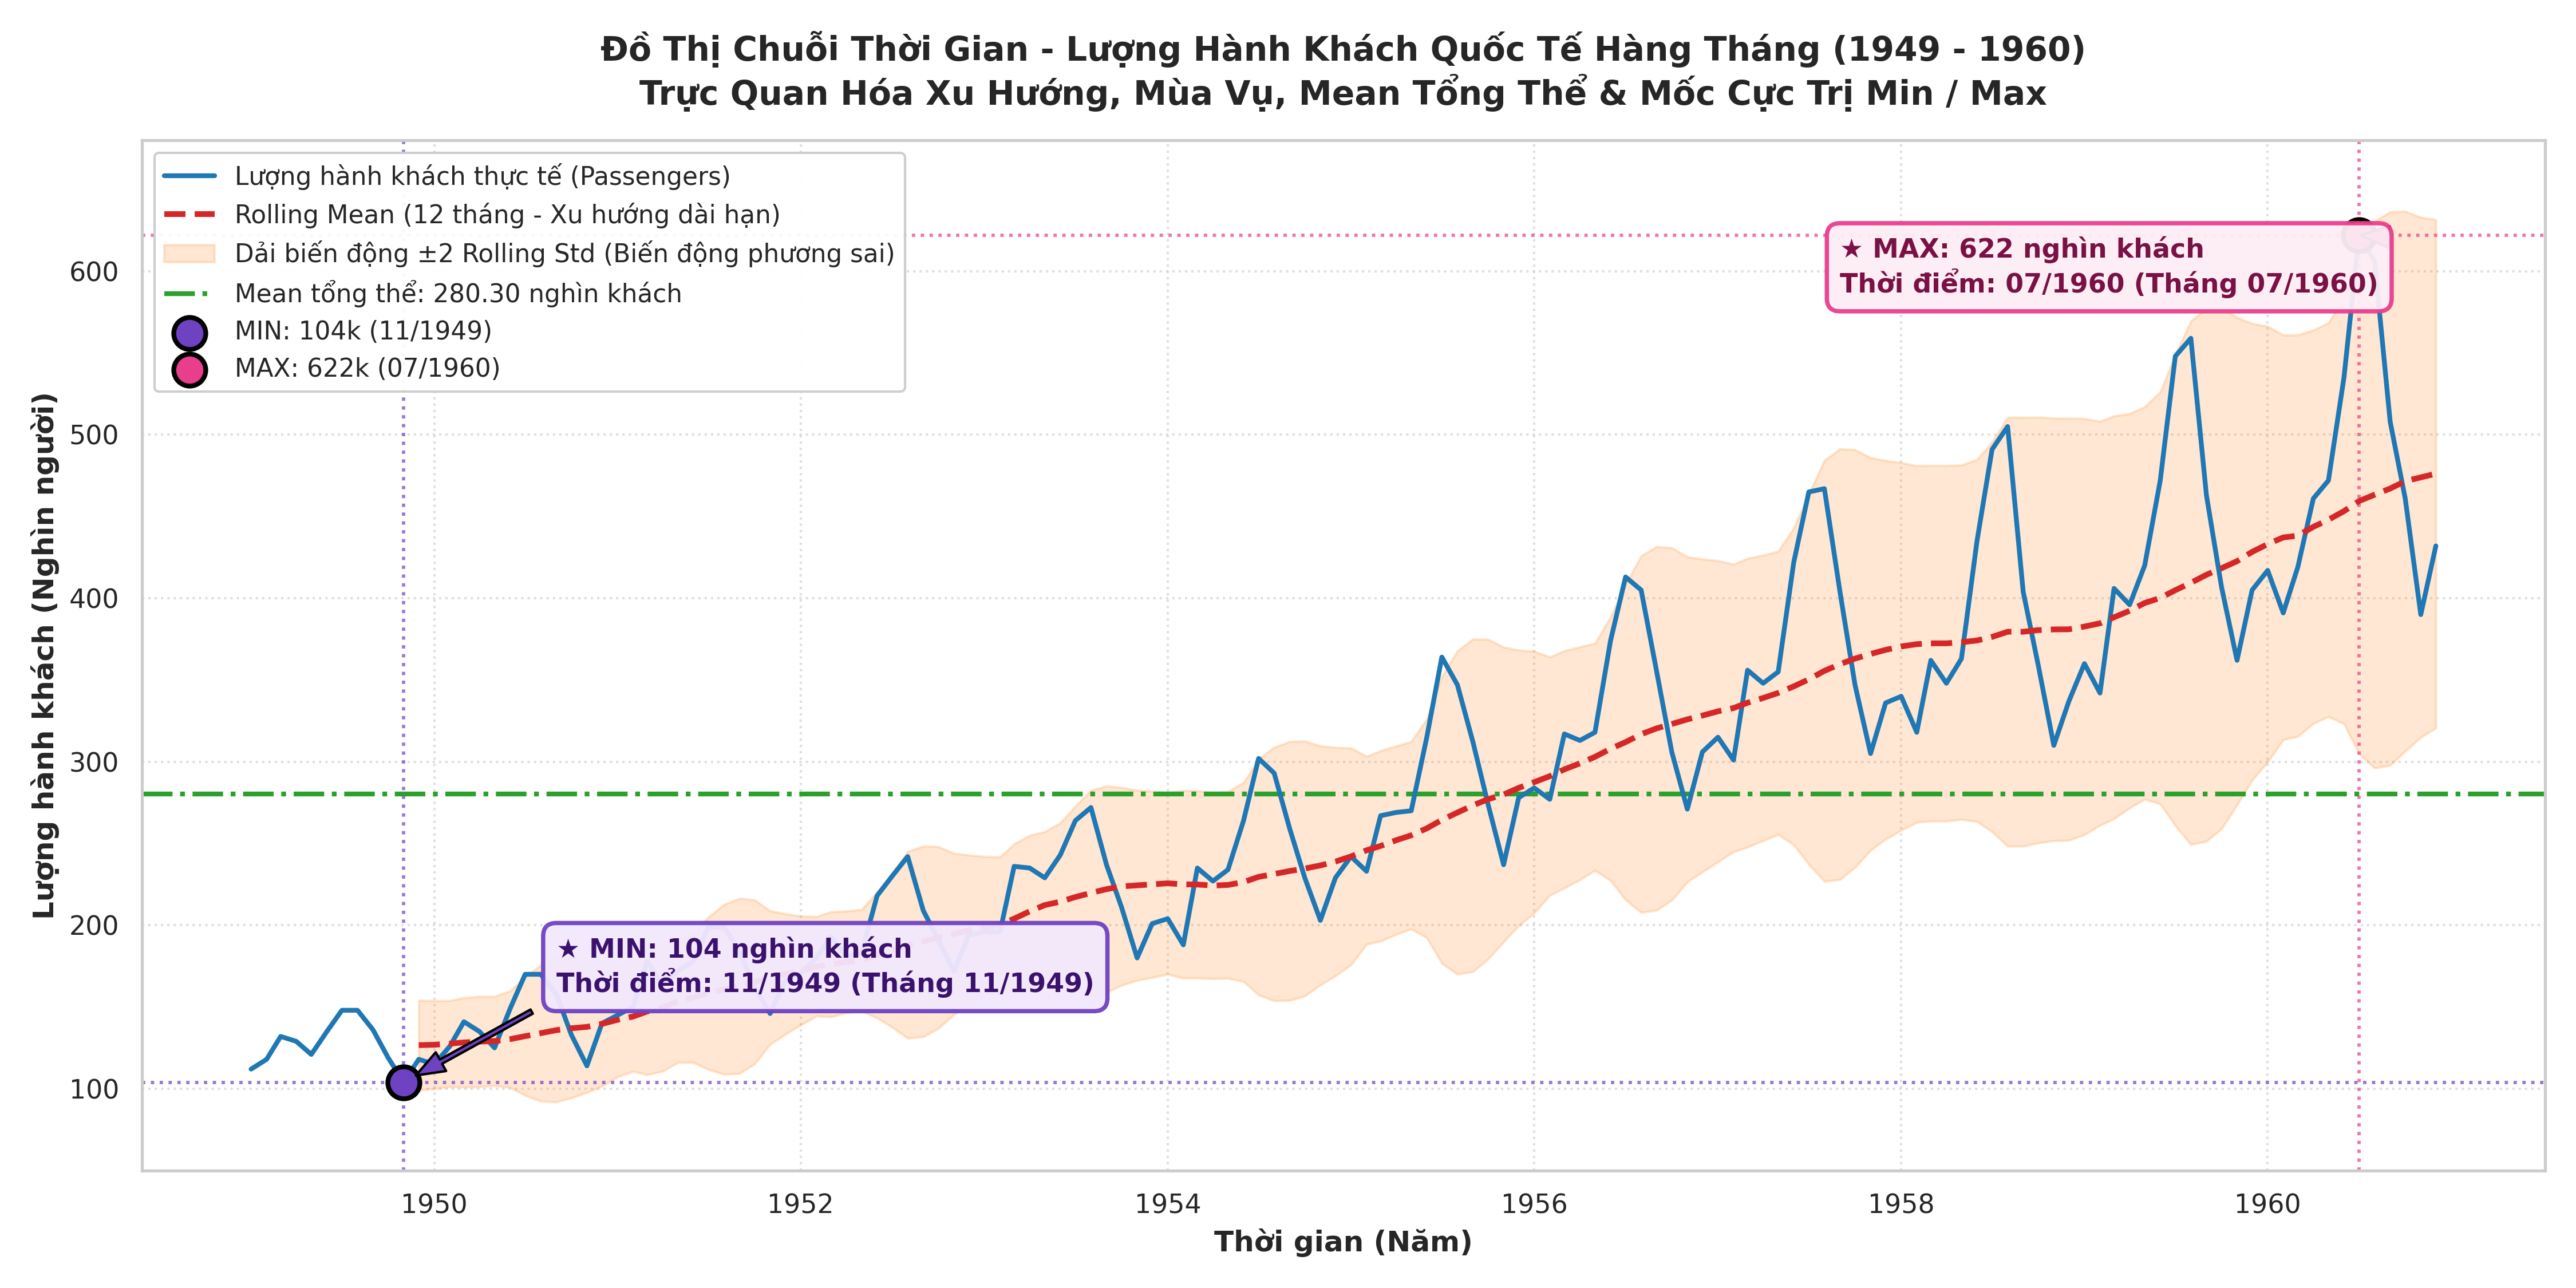

In [3]:
# 2. Vẽ đồ thị chuỗi thời gian kết hợp Rolling Mean, Rolling Std, Mean, Min & Max
mean_val = df['Passengers'].mean()
min_val = df['Passengers'].min()
min_date = df['Passengers'].idxmin()
max_val = df['Passengers'].max()
max_date = df['Passengers'].idxmax()

rolling_mean = df['Passengers'].rolling(window=12).mean()
rolling_std = df['Passengers'].rolling(window=12).std()

plt.figure(figsize=(15, 7.5))

# 1. Vẽ chuỗi thực tế & Rolling statistics
plt.plot(df.index, df['Passengers'], color='#1f77b4', linewidth=2.0, label='Lượng hành khách thực tế (Passengers)', zorder=3)
plt.plot(rolling_mean, color='#d62728', linestyle='--', linewidth=2.4, label='Rolling Mean (12 tháng - Xu hướng)', zorder=4)
plt.fill_between(df.index, rolling_mean - 2 * rolling_std, rolling_mean + 2 * rolling_std, color='#ff7f0e', alpha=0.18, label='Dải biến động ±2 Rolling Std')

# 2. Đường Mean tổng thể
plt.axhline(mean_val, color='#2ca02c', linestyle='-.', linewidth=2.0, label=f'Mean tổng thể: {mean_val:.2f} nghìn khách', zorder=2)

# 3. Điểm MIN (104 tại 11/1949)
plt.axhline(min_val, color='#6f42c1', linestyle=':', linewidth=1.4, alpha=0.7)
plt.axvline(min_date, color='#6f42c1', linestyle=':', linewidth=1.4, alpha=0.7)
plt.scatter([min_date], [min_val], color='#6f42c1', s=180, zorder=6, edgecolors='black', linewidth=2, label=f'MIN: {min_val}k ({min_date.strftime("%m/%Y")})')
plt.annotate(
    f'★ MIN: {min_val} nghìn khách\nThời điểm: {min_date.strftime("%m/%Y")} (Tháng 11/1949)',
    xy=(min_date, min_val),
    xytext=(min_date + pd.DateOffset(months=10), min_val + 55),
    arrowprops=dict(facecolor='#6f42c1', edgecolor='black', shrink=0.08, width=2, headwidth=9),
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#f3e8fd', edgecolor='#6f42c1', lw=1.8, alpha=0.95),
    fontsize=11, fontweight='bold', color='#3b116e', zorder=7
)

# 4. Điểm MAX (622 tại 07/1960)
plt.axhline(max_val, color='#e83e8c', linestyle=':', linewidth=1.4, alpha=0.7)
plt.axvline(max_date, color='#e83e8c', linestyle=':', linewidth=1.4, alpha=0.7)
plt.scatter([max_date], [max_val], color='#e83e8c', s=180, zorder=6, edgecolors='black', linewidth=2, label=f'MAX: {max_val}k ({max_date.strftime("%m/%Y")})')
plt.annotate(
    f'★ MAX: {max_val} nghìn khách\nThời điểm: {max_date.strftime("%m/%Y")} (Tháng 07/1960)',
    xy=(max_date, max_val),
    xytext=(max_date - pd.DateOffset(months=34), max_val - 35),
    arrowprops=dict(facecolor='#e83e8c', edgecolor='black', shrink=0.08, width=2, headwidth=9),
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#fdeef6', edgecolor='#e83e8c', lw=1.8, alpha=0.95),
    fontsize=11, fontweight='bold', color='#7a1144', zorder=7
)

plt.title('Đồ Thị Chuỗi Thời Gian - Lượng Hành Khách Quốc Tế Hàng Tháng (1949 - 1960)\nTrực Quan Hóa Xu Hướng, Mùa Vụ, Mean Tổng Thể & Mốc Cực Trị Min / Max', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Thời gian (Năm)', fontsize=12, fontweight='bold')
plt.ylabel('Hành khách (Nghìn người)', fontsize=12, fontweight='bold')
plt.ylim(50, 680)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.95, fontsize=10.5, edgecolor='#ccc')
plt.tight_layout()

os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/01_ts_plot_airline.png', dpi=300)
print(f'Mean tổng thể: {mean_val:.2f} nghìn khách')
print(f'MIN: {min_val} nghìn khách tại thời điểm {min_date.strftime("%Y-%m")} (Tháng 11/1949)')
print(f'MAX: {max_val} nghìn khách tại thời điểm {max_date.strftime("%Y-%m")} (Tháng 07/1960)')
plt.show()


## 3. Phân Rã Chuỗi Thời Gian Bằng Phương Pháp STL (Loess) & Khảo Sát Tính Nhân (Multiplicative)
### 📌 Phương pháp kiểm chứng dữ liệu:
- **Phương pháp STL (Seasonal and Trend decomposition using Loess):**
  - Sử dụng chuỗi các hồi quy cục bộ có trọng số (Loess).
  - Tách chuỗi $Y_t$ thành 3 thành phần:
    $$Y_t = T_t (\text{Trend}) + S_t (\text{Seasonal}) + R_t (\text{Residual})$$
  - **Ưu thế của STL:** Khắc phục triệt để nhược điểm của phân rã trung bình trượt cổ điển (classical decomposition): không bị mất dữ liệu ở hai đầu (không có giá trị NaN), đồng thời tham số `robust=True` giúp hạn chế ảnh hưởng của các giá trị ngoại lai (outliers).
- **Phát hiện đặc tính Nhân (Multiplicative Seasonality) của tập Airline Passengers:**
  - Quan sát thấy biên độ sóng mùa vụ tăng tỷ lệ thuận với mức độ của Trend (năm 1949 dao động khoảng $\pm 30$ nghìn người, đến năm 1960 dao động lên tới $\pm 150$ nghìn người).
  - Do đó, phần dư $R_t$ trong mô hình cộng bị phình to ở cuối chuỗi. Điều này chứng minh chuỗi gốc có cấu trúc dạng **Nhân tính**: $Y_t = T_t \times S_t \times R_t$, hoặc dạng cộng sau khi lấy Logarit: $\ln(Y_t) = \ln(T_t) + \ln(S_t) + \ln(R_t)$.


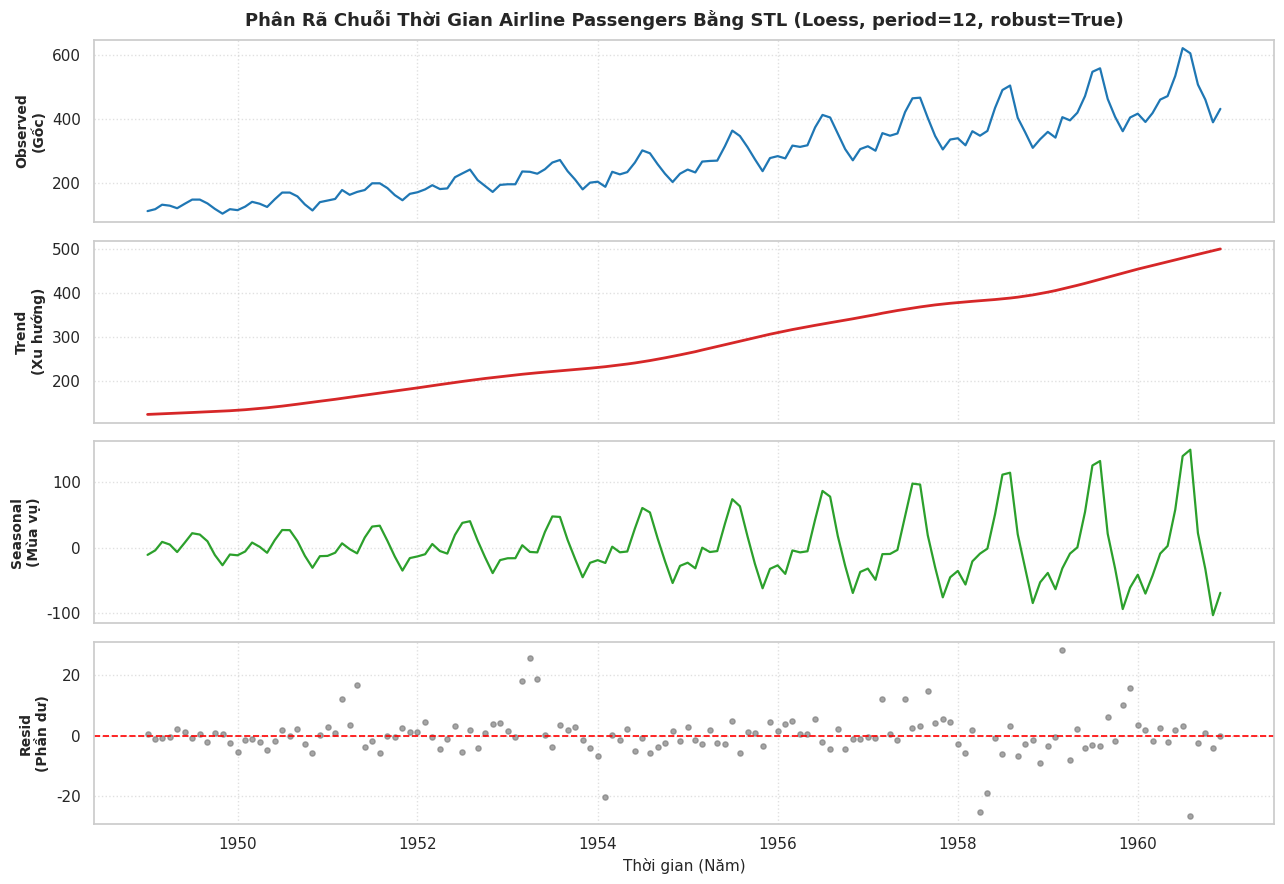

In [11]:
# 3. Phân rã chuỗi thời gian bằng phương pháp STL (Loess, period=12, robust=True)
stl = STL(df['Passengers'], period=12, robust=True)
res_stl = stl.fit()

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)

# 1. Observed (Chuỗi gốc)
axes[0].plot(res_stl.observed, color='#1f77b4', lw=1.6)
axes[0].set_ylabel('Observed\n(Gốc)', fontsize=10, fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].set_title('Phân Rã Chuỗi Thời Gian Airline Passengers Bằng STL (Loess, period=12, robust=True)', fontsize=13, fontweight='bold', pad=10)

# 2. Trend (Xu hướng)
axes[1].plot(res_stl.trend, color='#d62728', lw=2)
axes[1].set_ylabel('Trend\n(Xu hướng)', fontsize=10, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)

# 3. Seasonal (Mùa vụ)
axes[2].plot(res_stl.seasonal, color='#2ca02c', lw=1.6)
axes[2].set_ylabel('Seasonal\n(Mùa vụ)', fontsize=10, fontweight='bold')
axes[2].grid(True, linestyle=':', alpha=0.6)

# 4. Residual (Phần dư)
axes[3].scatter(df.index, res_stl.resid, color='#7f7f7f', s=14, alpha=0.7)
axes[3].axhline(0.0, color='red', linestyle='--', lw=1.2)
axes[3].set_ylabel('Resid\n(Phần dư)', fontsize=10, fontweight='bold')
axes[3].set_xlabel('Thời gian (Năm)', fontsize=11)
axes[3].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/01_decomposition_airline.png', dpi=300)
plt.show()


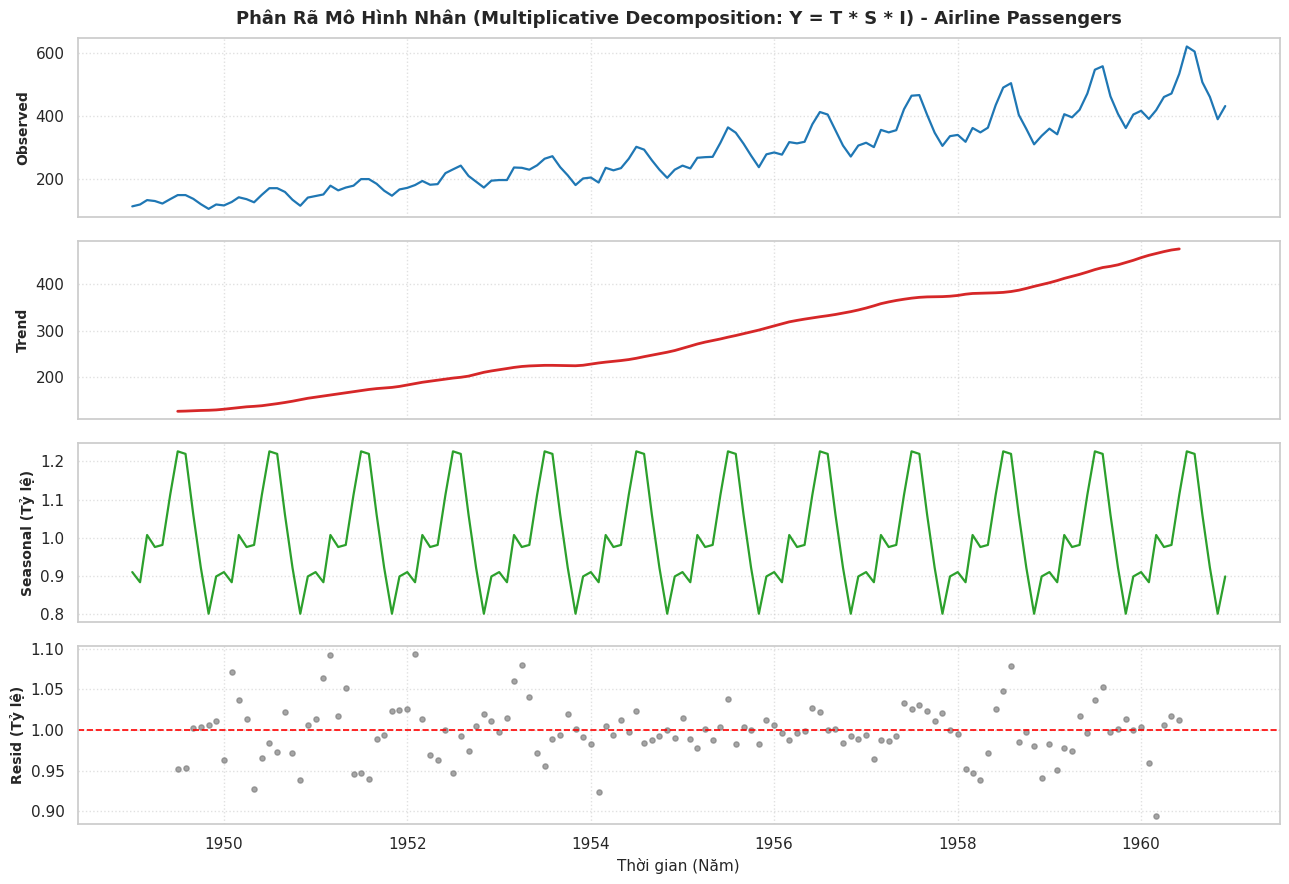

In [12]:
# Bổ sung nâng cao: Phân rã mô hình Nhân (Multiplicative Model: Y = T * S * I)
# Phương pháp này giúp kiểm chứng tính chất biên độ mùa vụ tăng tỷ lệ thuận với xu hướng
res_mult = seasonal_decompose(df['Passengers'], model='multiplicative', period=12)

fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)

axes[0].plot(res_mult.observed, color='#1f77b4', lw=1.6)
axes[0].set_ylabel('Observed', fontsize=10, fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.6)
axes[0].set_title('Phân Rã Mô Hình Nhân (Multiplicative Decomposition: Y = T * S * I) - Airline Passengers', fontsize=13, fontweight='bold', pad=10)

axes[1].plot(res_mult.trend, color='#d62728', lw=2)
axes[1].set_ylabel('Trend', fontsize=10, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].plot(res_mult.seasonal, color='#2ca02c', lw=1.6)
axes[2].set_ylabel('Seasonal (Tỷ lệ)', fontsize=10, fontweight='bold')
axes[2].grid(True, linestyle=':', alpha=0.6)

axes[3].scatter(df.index, res_mult.resid, color='#7f7f7f', s=14, alpha=0.7)
axes[3].axhline(1.0, color='red', linestyle='--', lw=1.2)
axes[3].set_ylabel('Resid (Tỷ lệ)', fontsize=10, fontweight='bold')
axes[3].set_xlabel('Thời gian (Năm)', fontsize=11)
axes[3].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/01_decomposition_multiplicative_airline.png', dpi=300)
plt.show()


### 📌 Bổ Sung: Khảo Sát Lược Đồ Tự Tương Quan (ACF) Của Thành Phần Phần Dư (Resid)
- **Mục tiêu phương pháp luận:**
  Sau khi bóc tách Xu hướng (Trend) và Mùa vụ (Seasonal), thành phần Phần dư (Residual $R_t$ hoặc $I_t$) lý tưởng phải mang đặc trưng của **Nhiễu trắng (White Noise)**:
  1. Không còn tự tương quan tuyến tính có ý nghĩa thống kê ở bất kỳ độ trễ nào ($\hat{\rho}_k \approx 0, \forall k \ge 1$).
  2. Toàn bộ các cột ACF phải nằm trọn vẹn bên trong dải tin cậy 95% Bartlett: $\left[ -\frac{1.96}{\sqrt{N}}, +\frac{1.96}{\sqrt{N}} \right]$.
  3. Không còn các đỉnh nhô mang tính chu kỳ mùa vụ tại các mốc bội số $s = 12, 24, 36$.
- **Ý nghĩa so sánh giữa 2 phương pháp:**
  - **Phần dư STL (Loess - Dạng cộng):** Khảo sát xem thuật toán hồi quy phi tham số Loess có khử sạch tính mùa vụ và xu hướng hay không.
  - **Phần dư Mô hình Nhân (Multiplicative):** Khảo sát xem chỉ số mùa vụ tĩnh cố định qua các năm có bóc tách hết mùa vụ hay vẫn để sót lại tính tự tương quan trong phần dư tỷ lệ.

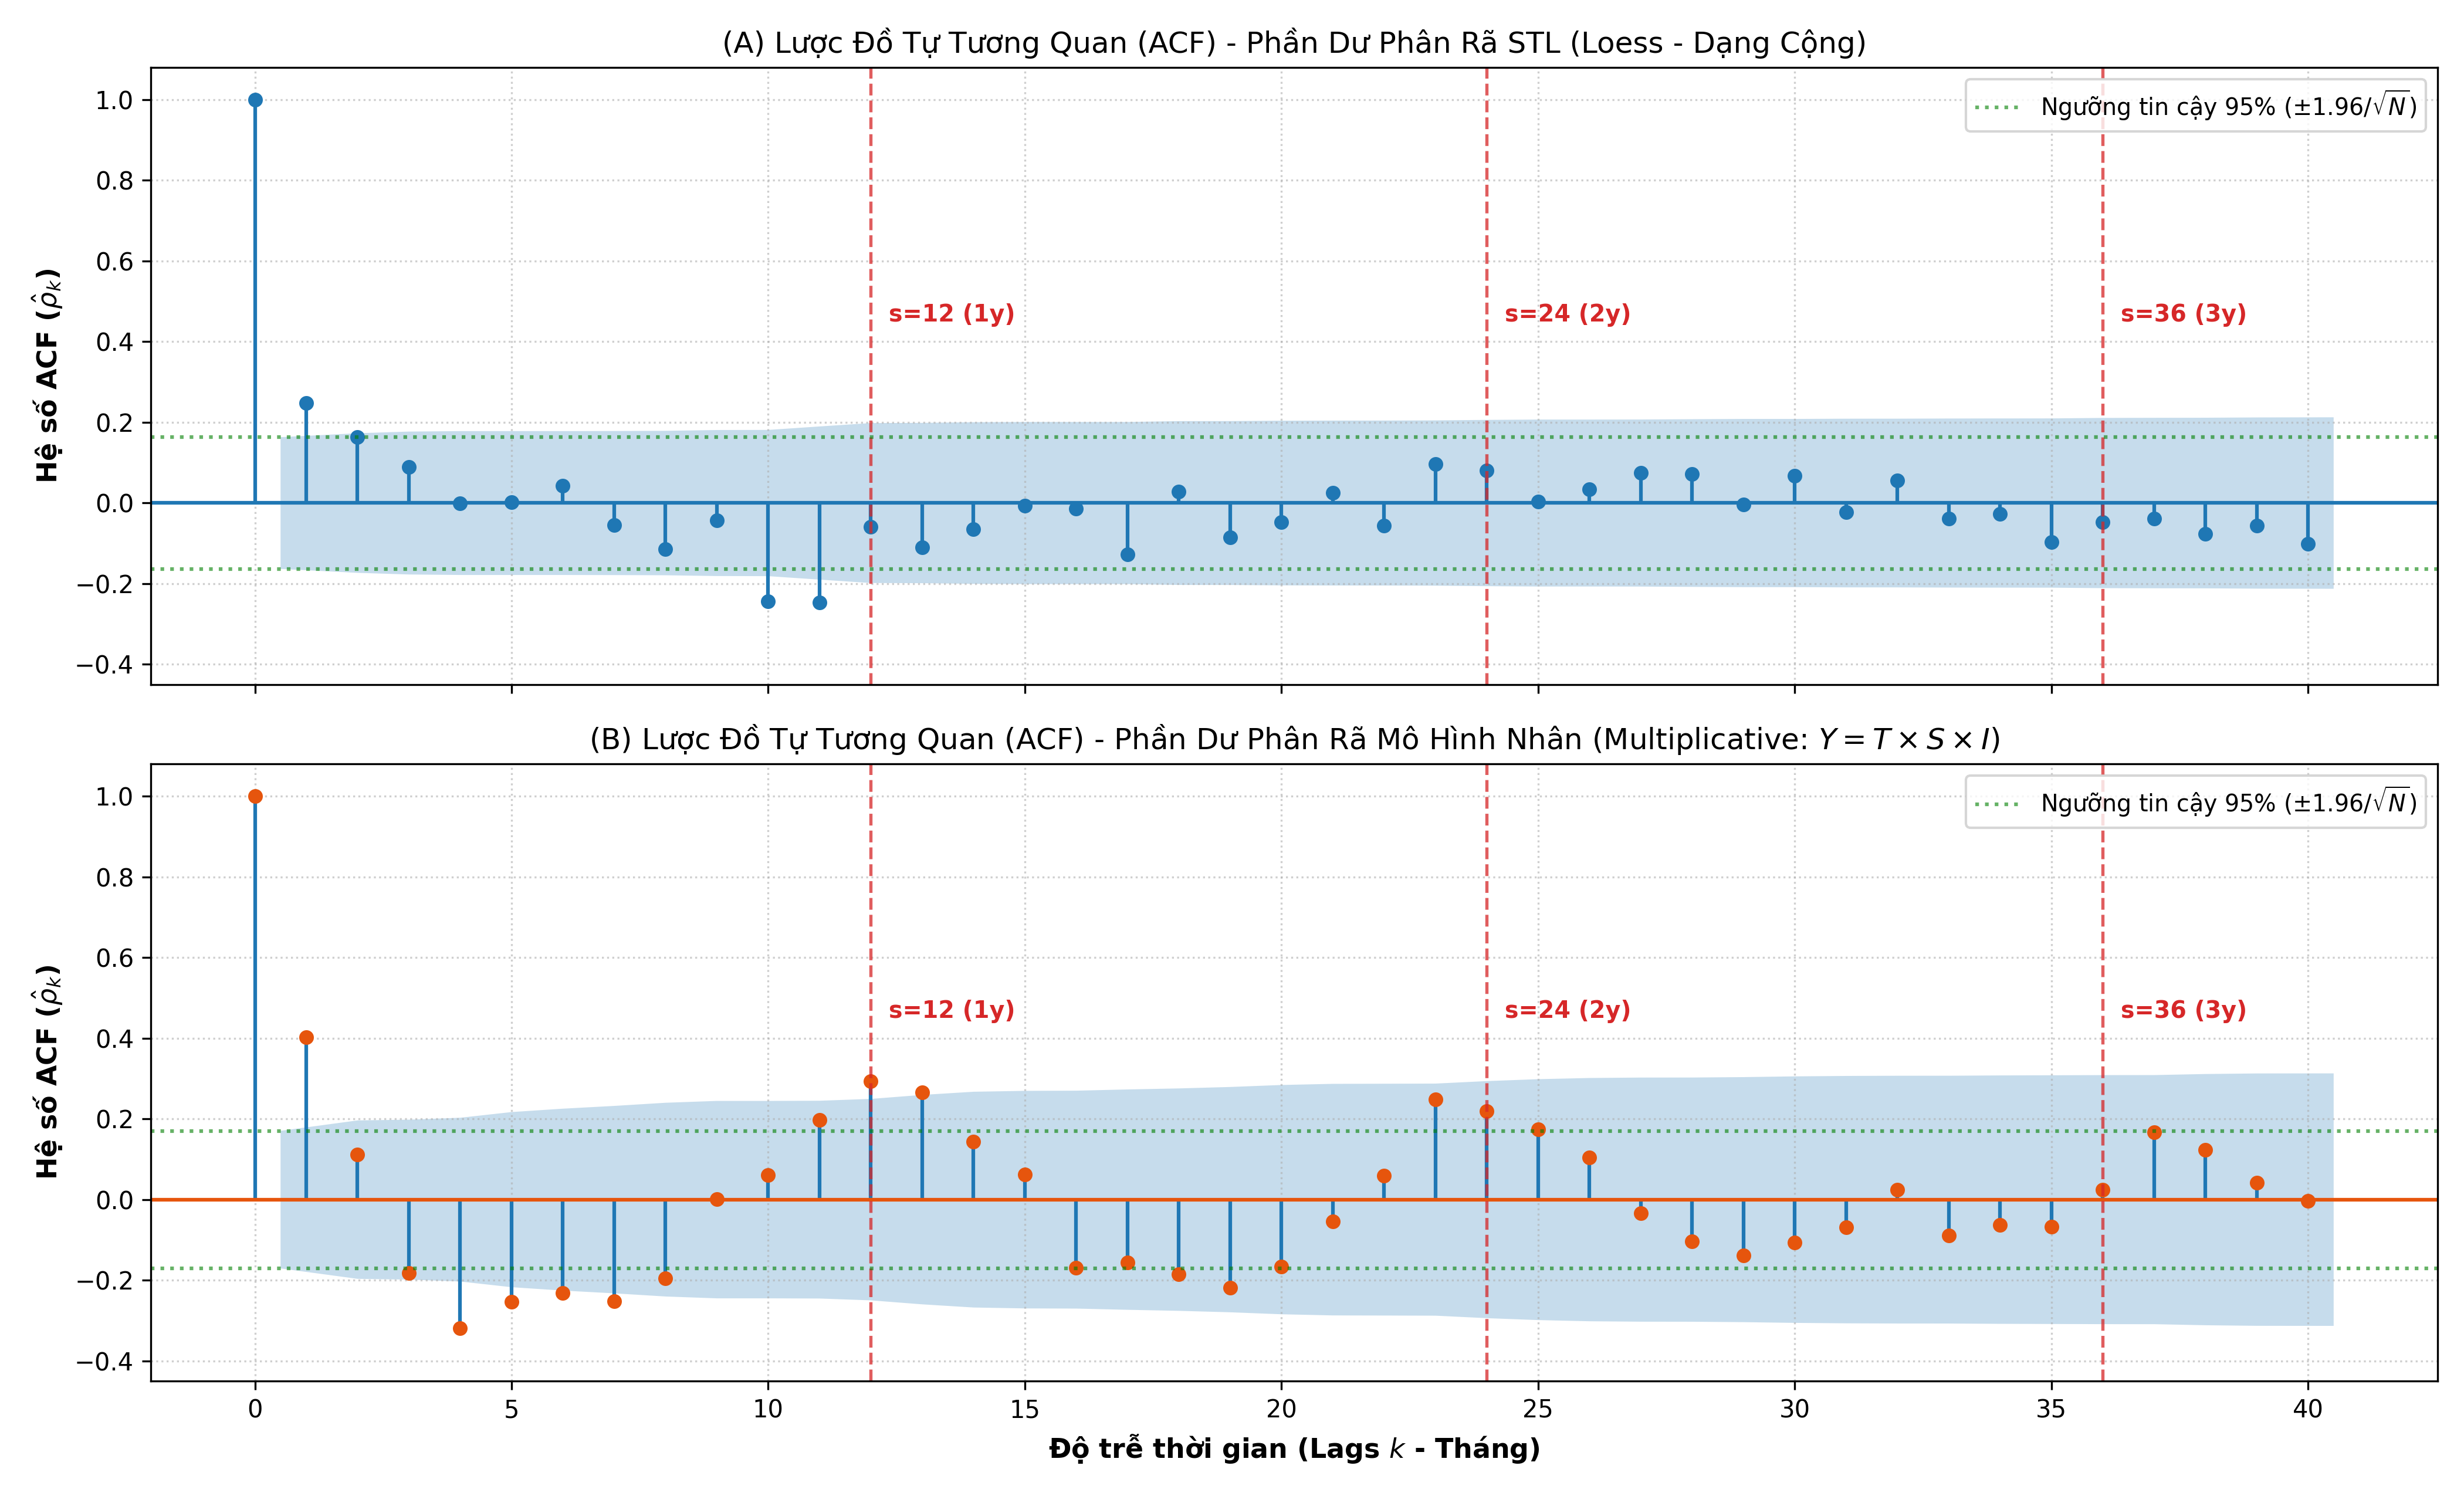

In [13]:
# 3.1. Khảo sát Lược đồ Tự tương quan (ACF) của phần dư (Resid) từ 2 phương pháp phân rã
fig, axes = plt.subplots(2, 1, figsize=(14, 8.5), sharex=True)

# 1. ACF của phần dư STL (Loess - Dạng cộng)
plot_acf(res_stl.resid, lags=40, ax=axes[0], alpha=0.05, color='#1f77b4',
         title='(A) Lược Đồ Tự Tương Quan (ACF) - Phần Dư Phân Rã STL (Loess - Dạng Cộng)')
axes[0].set_ylabel(r'Hệ số ACF ($\hat{\rho}_k$)', fontsize=11, fontweight='bold')
axes[0].set_ylim(-0.45, 1.08)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Đánh dấu các mốc lag mùa vụ chu kỳ s = 12 tháng
for lag in [12, 24, 36]:
    axes[0].axvline(x=lag, color='#d62728', linestyle='--', alpha=0.75, lw=1.3)
    axes[0].text(lag + 0.35, 0.45, f's={lag} ({lag//12}y)', color='#d62728', fontsize=9.5, fontweight='bold')

axes[0].axhline(1.96 / np.sqrt(len(res_stl.resid)), color='green', linestyle=':', alpha=0.6, label=r'Ngưỡng tin cậy 95% ($\pm 1.96/\sqrt{N}$)')
axes[0].axhline(-1.96 / np.sqrt(len(res_stl.resid)), color='green', linestyle=':', alpha=0.6)
axes[0].legend(loc='upper right', frameon=True, fontsize=9.5)

# 2. ACF của phần dư Mô hình Nhân (Multiplicative Decomposition: Y = T * S * I)
resid_mult_clean = res_mult.resid.dropna()
plot_acf(resid_mult_clean, lags=40, ax=axes[1], alpha=0.05, color='#e6550d',
         title=r'(B) Lược Đồ Tự Tương Quan (ACF) - Phần Dư Phân Rã Mô Hình Nhân (Multiplicative: $Y = T \times S \times I$)')
axes[1].set_xlabel('Độ trễ thời gian (Lags $k$ - Tháng)', fontsize=11, fontweight='bold')
axes[1].set_ylabel(r'Hệ số ACF ($\hat{\rho}_k$)', fontsize=11, fontweight='bold')
axes[1].set_ylim(-0.45, 1.08)
axes[1].grid(True, linestyle=':', alpha=0.6)

for lag in [12, 24, 36]:
    axes[1].axvline(x=lag, color='#d62728', linestyle='--', alpha=0.75, lw=1.3)
    axes[1].text(lag + 0.35, 0.45, f's={lag} ({lag//12}y)', color='#d62728', fontsize=9.5, fontweight='bold')

axes[1].axhline(1.96 / np.sqrt(len(resid_mult_clean)), color='green', linestyle=':', alpha=0.6, label=r'Ngưỡng tin cậy 95% ($\pm 1.96/\sqrt{N}$)')
axes[1].axhline(-1.96 / np.sqrt(len(resid_mult_clean)), color='green', linestyle=':', alpha=0.6)
axes[1].legend(loc='upper right', frameon=True, fontsize=9.5)

plt.tight_layout()
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/01_acf_resid_decomposition_airline.png', dpi=300)

# Đồng thời lưu 2 file riêng lẻ phục vụ báo cáo chuyên biệt
fig_stl, ax_s = plt.subplots(figsize=(13, 4.5))
plot_acf(res_stl.resid, lags=40, ax=ax_s, alpha=0.05, color='#1f77b4', title='Lược Đồ Tự Tương Quan (ACF) - Phần Dư Phân Rã STL (Loess - Dạng Cộng)')
for lag in [12, 24, 36]:
    ax_s.axvline(x=lag, color='#d62728', linestyle='--', alpha=0.75, lw=1.3)
    ax_s.text(lag + 0.35, 0.45, f's={lag} ({lag//12}y)', color='#d62728', fontsize=9.5, fontweight='bold')
ax_s.set_xlabel('Độ trễ thời gian (Lags $k$ - Tháng)', fontsize=11, fontweight='bold')
ax_s.set_ylabel(r'Hệ số ACF ($\hat{\rho}_k$)', fontsize=11, fontweight='bold')
ax_s.set_ylim(-0.45, 1.08)
ax_s.grid(True, linestyle=':', alpha=0.6)
ax_s.axhline(1.96 / np.sqrt(len(res_stl.resid)), color='green', linestyle=':', alpha=0.6, label=r'Ngưỡng tin cậy 95% ($\pm 1.96/\sqrt{N}$)')
ax_s.axhline(-1.96 / np.sqrt(len(res_stl.resid)), color='green', linestyle=':', alpha=0.6)
ax_s.legend(loc='upper right', frameon=True, fontsize=9.5)
fig_stl.tight_layout()
fig_stl.savefig('../docs/images/01_acf_resid_stl_airline.png', dpi=300)
plt.close(fig_stl)

fig_m, ax_m = plt.subplots(figsize=(13, 4.5))
plot_acf(resid_mult_clean, lags=40, ax=ax_m, alpha=0.05, color='#e6550d', title='Lược Đồ Tự Tương Quan (ACF) - Phần Dư Phân Rã Mô Hình Nhân (Multiplicative)')
for lag in [12, 24, 36]:
    ax_m.axvline(x=lag, color='#d62728', linestyle='--', alpha=0.75, lw=1.3)
    ax_m.text(lag + 0.35, 0.45, f's={lag} ({lag//12}y)', color='#d62728', fontsize=9.5, fontweight='bold')
ax_m.set_xlabel('Độ trễ thời gian (Lags $k$ - Tháng)', fontsize=11, fontweight='bold')
ax_m.set_ylabel(r'Hệ số ACF ($\hat{\rho}_k$)', fontsize=11, fontweight='bold')
ax_m.set_ylim(-0.45, 1.08)
ax_m.grid(True, linestyle=':', alpha=0.6)
ax_m.axhline(1.96 / np.sqrt(len(resid_mult_clean)), color='green', linestyle=':', alpha=0.6, label=r'Ngưỡng tin cậy 95% ($\pm 1.96/\sqrt{N}$)')
ax_m.axhline(-1.96 / np.sqrt(len(resid_mult_clean)), color='green', linestyle=':', alpha=0.6)
ax_m.legend(loc='upper right', frameon=True, fontsize=9.5)
fig_m.tight_layout()
fig_m.savefig('../docs/images/01_acf_resid_multiplicative_airline.png', dpi=300)
plt.close(fig_m)

plt.show()

## 4. Khảo Sát Đặc Trưng Mùa Vụ & Xu Hướng Qua Boxplot Đa Chiều
### 📌 Phương pháp kiểm chứng dữ liệu:
- **Month-wise Boxplot (Khảo sát chu kỳ Mùa vụ nội năm):**
  - Nhóm dữ liệu theo 12 tháng (từ Tháng 1 đến Tháng 12) trên toàn bộ 12 năm.
  - Cho biết tháng nào là **mùa cao điểm (Peak)** và tháng nào là **mùa thấp điểm (Trough)** của ngành hàng không quốc tế.
  - Phản ánh độ biến động nội bộ của từng tháng cụ thể.
- **Year-wise Boxplot (Khảo sát Xu hướng dài hạn & Độ phân tán):**
  - Nhóm dữ liệu theo từng năm từ 1949 đến 1960.
  - Đường trung vị (median) tịnh tiến lên phía trên qua từng năm khẳng định xu hướng tăng trưởng bền vững (Secular Upward Trend).
  - Chiều cao hộp boxplot (khoảng phân vị $IQR = Q_3 - Q_1$) dãn rộng qua các năm khẳng định thêm tính chất phương sai thay đổi (Heteroscedasticity).


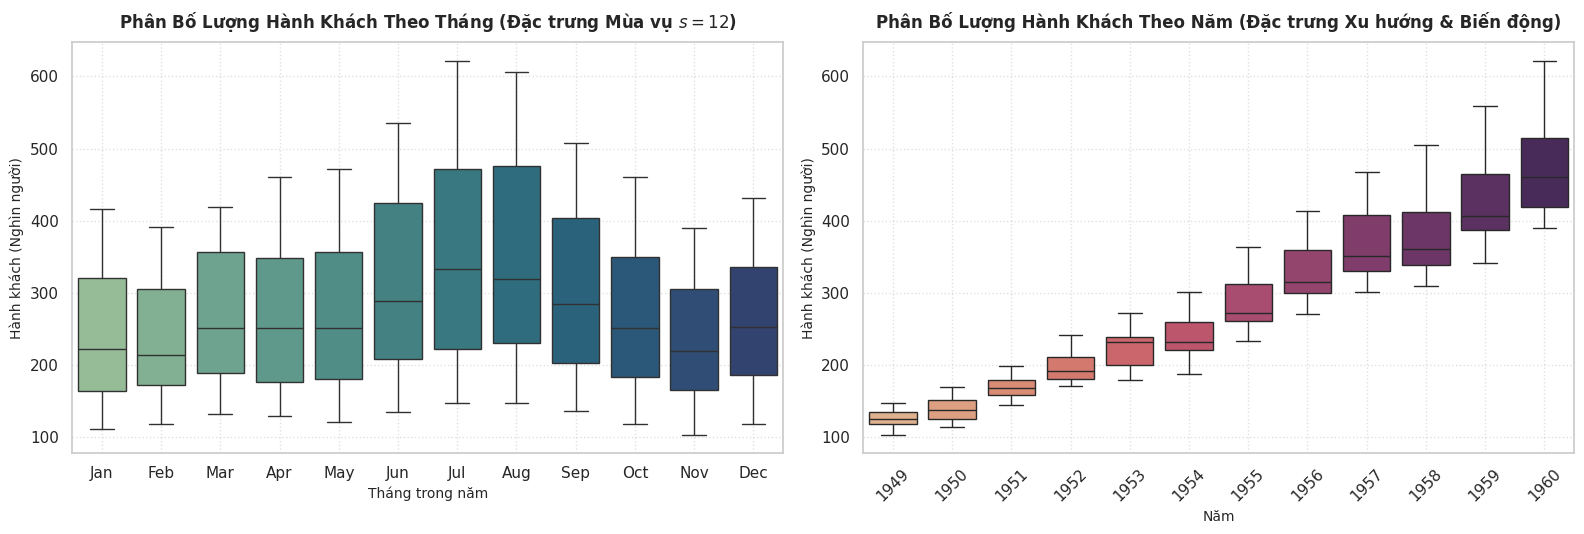

In [14]:
# 4. Khảo sát đặc trưng Mùa vụ & Xu hướng qua Boxplot đa chiều
df_box = df.copy()
df_box['Year'] = df_box.index.year
df_box['Month'] = df_box.index.strftime('%b')
months_order = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# Subplot 1: Month-wise Boxplot (Khảo sát tính Mùa vụ nội năm)
sns.boxplot(
    data=df_box, 
    x='Month', 
    y='Passengers', 
    order=months_order, 
    palette='crest', 
    hue='Month', 
    legend=False, 
    ax=axes[0]
)
axes[0].set_title('Phân Bố Lượng Hành Khách Theo Tháng (Đặc trưng Mùa vụ $s=12$)', fontsize=12, fontweight='bold', pad=10)
axes[0].set_xlabel('Tháng trong năm', fontsize=10)
axes[0].set_ylabel('Hành khách (Nghìn người)', fontsize=10)
axes[0].grid(True, linestyle=':', alpha=0.6)

# Subplot 2: Year-wise Boxplot (Khảo sát Xu hướng dài hạn & Phương sai)
sns.boxplot(
    data=df_box, 
    x='Year', 
    y='Passengers', 
    palette='flare', 
    hue='Year', 
    legend=False, 
    ax=axes[1]
)
axes[1].set_title('Phân Bố Lượng Hành Khách Theo Năm (Đặc trưng Xu hướng & Biến động)', fontsize=12, fontweight='bold', pad=10)
axes[1].set_xlabel('Năm', fontsize=10)
axes[1].set_ylabel('Hành khách (Nghìn người)', fontsize=10)
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/01_boxplots_airline.png', dpi=300)
plt.show()


## 5. Phân Tích Lược Đồ Tự Tương Quan Sơ Bộ (ACF Plot của Chuỗi Gốc)
### 📌 Phương pháp kiểm chứng dữ liệu:
- **Hệ số tự tương quan (Autocorrelation Coefficient $\rho_k$):**
  $$\rho_k = \frac{\operatorname{Cov}(Y_t, Y_{t-k})}{\operatorname{Var}(Y_t)}$$
  Đo lường mức độ phụ thuộc tuyến tính giữa giá trị hiện tại $Y_t$ và giá trị trễ quá khứ $Y_{t-k}$.
- **Nhận diện tính dừng (Stationarity Identification):**
  - Đối với một chuỗi dừng (Stationary Series), các hệ số ACF sẽ suy giảm rất nhanh về 0 theo hàm mũ (exponential decay) hoặc tắt hẳn (die out) sau vài độ trễ đầu tiên.
  - Nếu hệ số ACF dương rất lớn tại lag 1 và **suy giảm tuyến tính cực kỳ chậm (Slow Linear Decay)** qua hàng chục lags $\implies$ Dấu hiệu kinh điển của chuỗi **không dừng (Non-stationary)** do có xu hướng mạnh.
- **Nhận diện chu kỳ mùa vụ ($s=12$):**
  - Biểu đồ ACF xuất hiện các đỉnh sóng nhô cao mang tính chu kỳ tại các độ trễ là bội số của 12: $k = 12, 24, 36,...$. Điều này khẳng định sự tồn tại của thành phần mùa vụ lặp lại hàng năm.


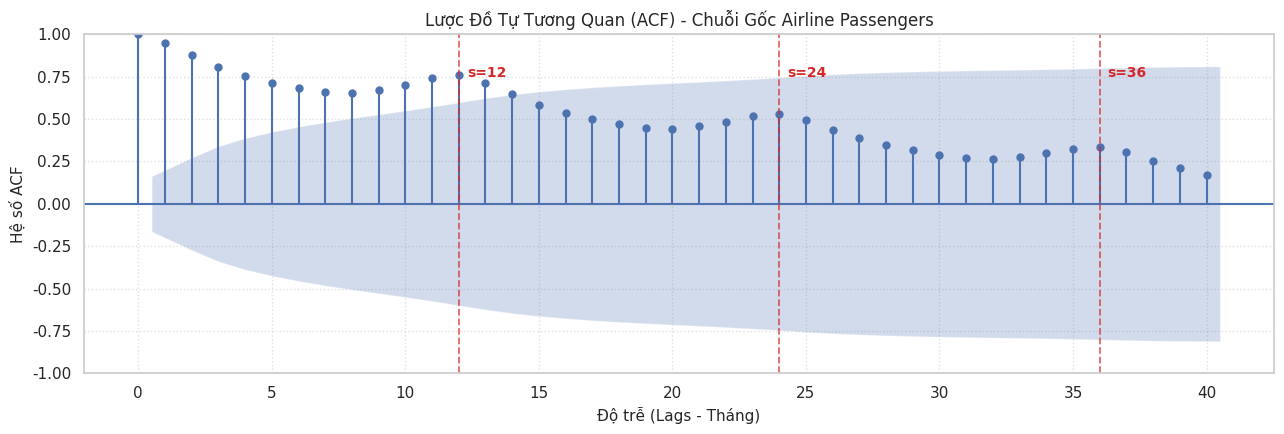

In [15]:
# 5. Phân tích Tự tương quan sơ bộ (ACF Plot của chuỗi gốc Airline Passengers)
fig, ax = plt.subplots(figsize=(13, 4.5))
plot_acf(df['Passengers'], lags=40, ax=ax, alpha=0.05, title='Lược Đồ Tự Tương Quan (ACF) - Chuỗi Gốc Airline Passengers')
ax.set_xlabel('Độ trễ (Lags - Tháng)', fontsize=11)
ax.set_ylabel('Hệ số ACF', fontsize=11)
ax.grid(True, linestyle=':', alpha=0.6)

# Đánh dấu các mốc lag mùa vụ chu kỳ s = 12 tháng
for lag in [12, 24, 36]:
    ax.axvline(x=lag, color='#d62728', linestyle='--', alpha=0.7, lw=1.3)
    ax.text(lag + 0.3, 0.75, f's={lag}', color='#d62728', fontsize=10, fontweight='bold')

plt.tight_layout()
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/01_acf_airline.png', dpi=300)
plt.show()


## 📝 Đúc Kết Nhanh Kết Quả EDA (Phần 1)

1. **Xu hướng:** Tăng trưởng bền vững, dốc mạnh từ ~120k lên >500k hành khách (tăng gần 400% sau 12 năm).
2. **Mùa vụ:** Chu kỳ hàng năm cố định $s=12$ tháng; đỉnh cao điểm hè (tháng 7-8), đáy thấp điểm đông (tháng 11-2). Biên độ dãn rộng theo xu hướng (Mùa vụ Nhân tính - Multiplicative).
3. **Tính dừng:** Vi phạm nghiêm trọng cả về kỳ vọng ($\mathbb{E}[Y_t] \neq \text{const}$), phương sai ($\operatorname{Var}(Y_t) \neq \text{const}$) và hàm tự hiệp phương sai $\implies$ **Chuỗi không dừng (Strictly Non-stationary)**.

$\implies$ Kết quả EDA khẳng định **bắt buộc phải sử dụng Sai phân kép ($d=1, D=1, s=12$)** để triệt tiêu xu hướng và mùa vụ. Chuyển tiếp sang **Phần 2: Bài Tập Nâng Cao Mô Hình Hóa Mùa Vụ Với SARIMA**.


---
# PHẦN 2: BÀI TẬP NÂNG CAO - MÔ HÌNH HÓA MÙA VỤ VỚI SARIMA (AIRLINE PASSENGERS)
> **Mục tiêu học thuật:** Triển khai quy trình 7 bước chuẩn mực của Box & Jenkins mở rộng mùa vụ, xây dựng mô hình $\text{SARIMA}(p, d, q) \times (P, D, Q)_{12}$ và so sánh hiệu năng dự báo ngoài mẫu với mô hình $\text{ARIMA}$ phi mùa vụ.

### Bước 1: Trực quan hóa chuỗi thời gian & Nhận diện mùa vụ ($s = 12$)
- **Mục tiêu trực quan:** Đánh giá chi tiết cấu trúc dữ liệu qua từng mốc tháng, làm nổi bật chu kỳ mùa vụ $s = 12$, dải cao điểm du lịch hè, đường kỳ vọng trung bình (Mean), xu hướng dài hạn (Rolling Mean 12m) và hai mốc cực trị lịch sử (MIN, MAX).
- **Tính năng tương tác (Interactive Inspection):** Hỗ trợ rê chuột (hover) vào từng điểm tháng để tra cứu tức thì thông tin: thời điểm, số lượng hành khách, đặc thù mùa vụ và độ lệch so với kỳ vọng trung bình.


<Figure Plotly Interactive>

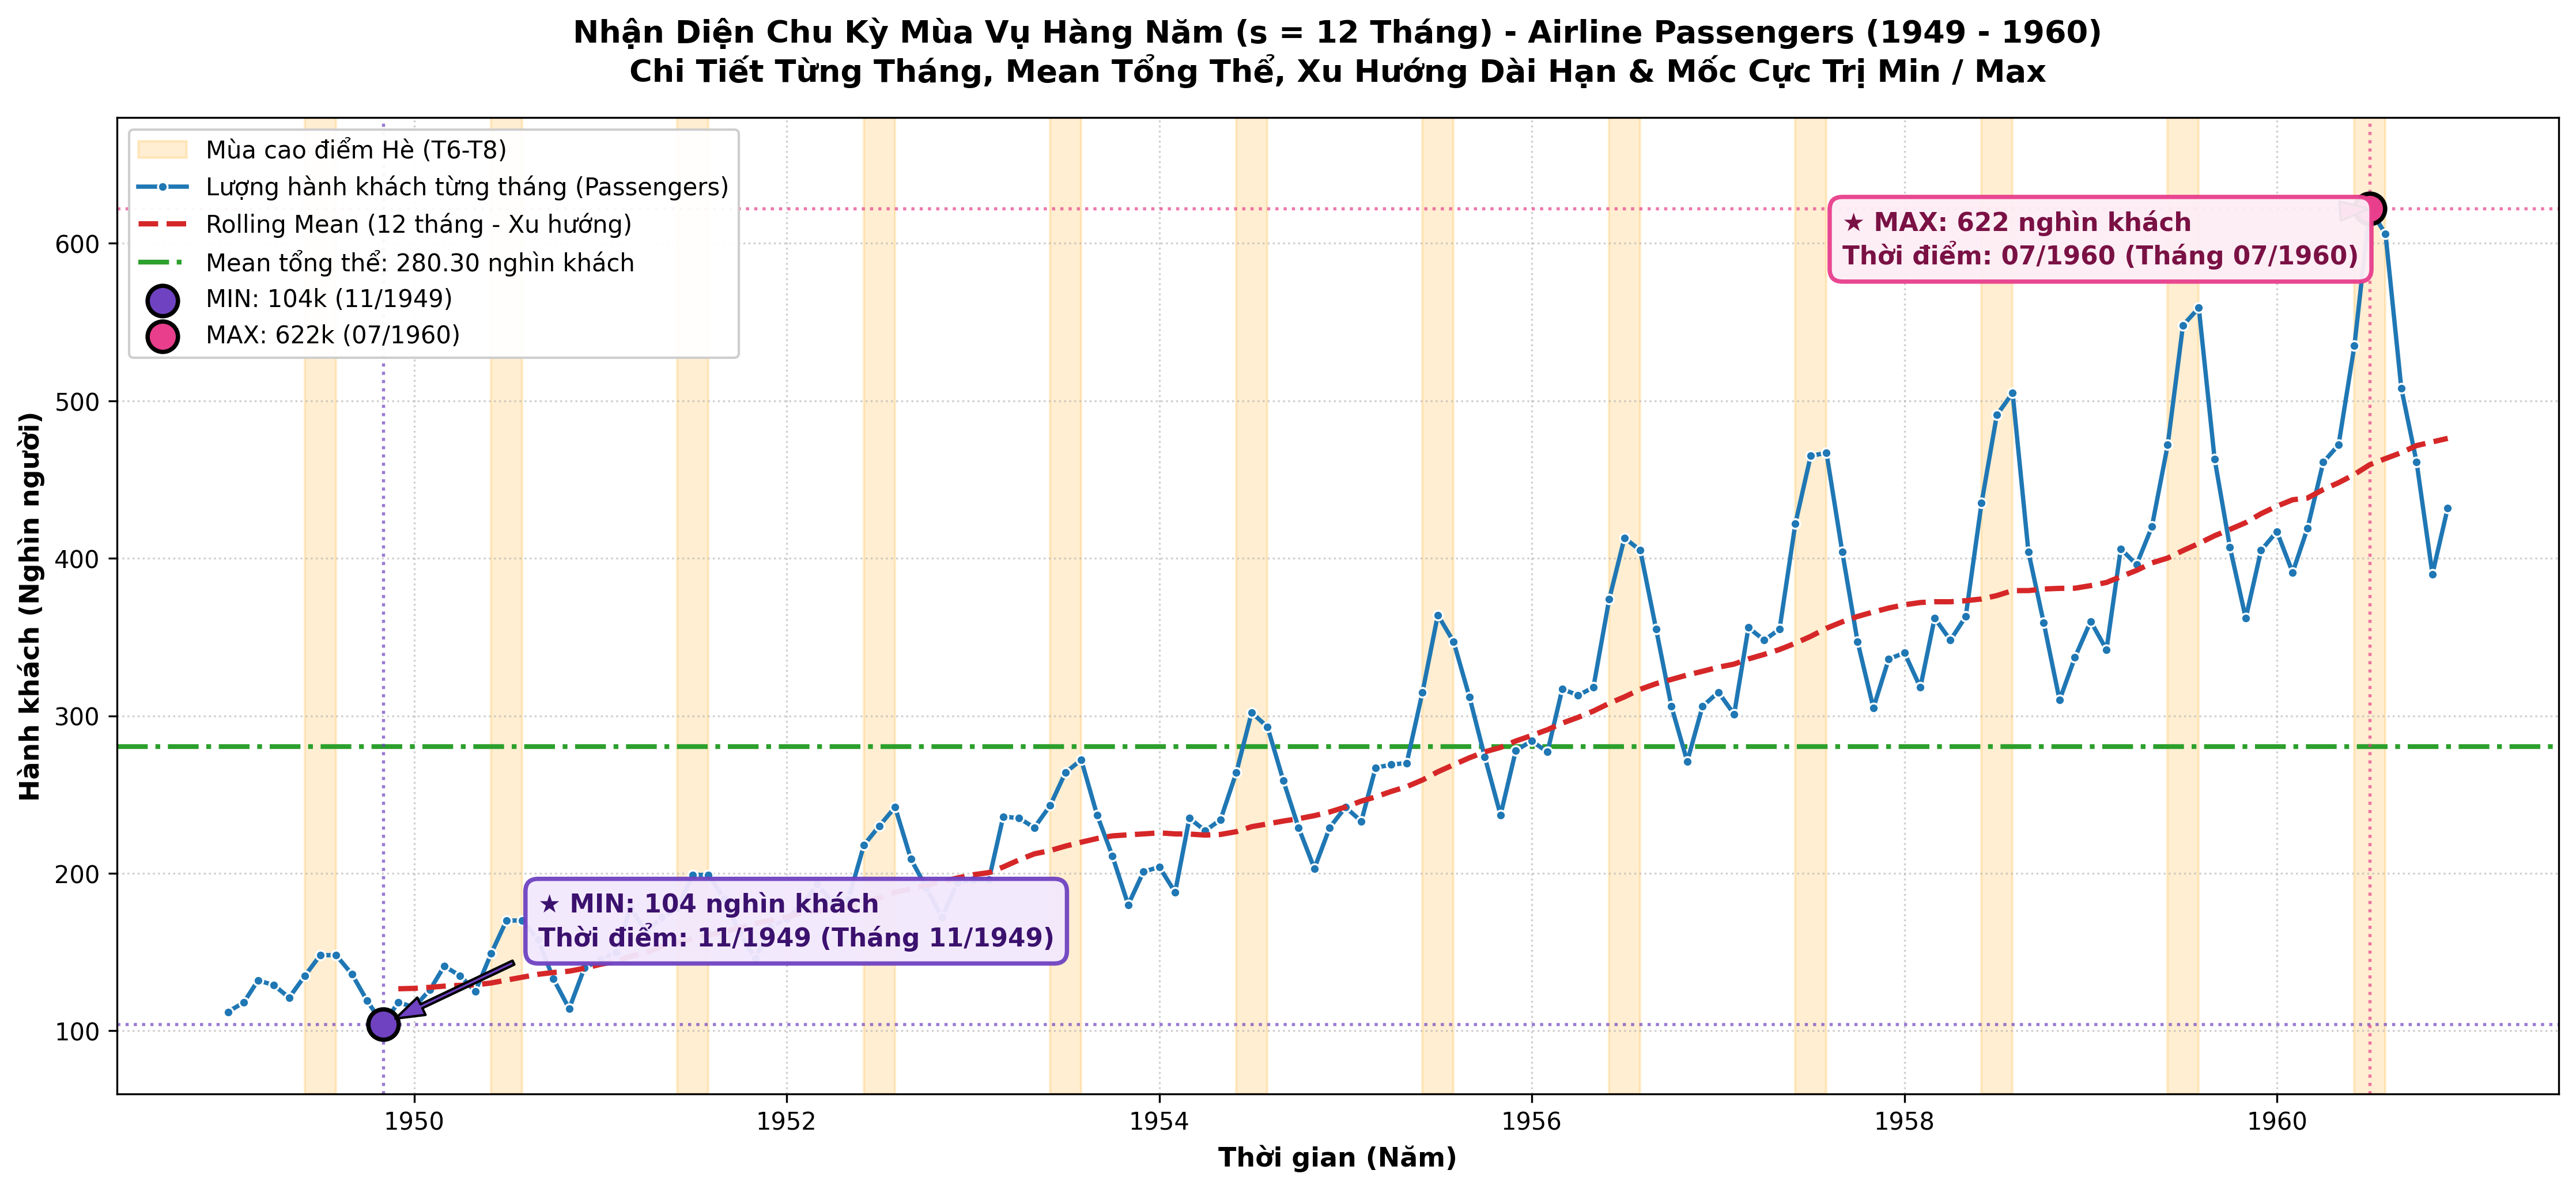

Mean tổng thể: 280.30 nghìn khách
MIN: 104 nghìn khách tại thời điểm 1949-11 (Tháng 11/1949)
MAX: 622 nghìn khách tại thời điểm 1960-07 (Tháng 07/1960)
Đặc trưng nhận diện: Chu kỳ mùa vụ cố định s = 12 tháng, biên độ hè mở rộng tỷ lệ thuận với mức độ tăng trưởng.
Đã kích hoạt chế độ tương tác Plotly: Bạn có thể rê chuột vào từng điểm để tra cứu chi tiết số khách của từng tháng!


In [8]:
# Bước 1: Trực quan hóa chuỗi thời gian & Nhận diện mùa vụ s = 12 (Tĩnh & Tương tác Hover)
import plotly.graph_objects as go

mean_val = df['Passengers'].mean()
min_val = df['Passengers'].min()
min_date = df['Passengers'].idxmin()
max_val = df['Passengers'].max()
max_date = df['Passengers'].idxmax()
rolling_mean = df['Passengers'].rolling(window=12).mean()

# -------------------------------------------------------------
# 1. VẼ ĐỒ THỊ TĨNH CHI TIẾT (Lưu file ảnh 06_air_eda_seasonality.png)
# -------------------------------------------------------------
plt.figure(figsize=(15, 7))

# Dải tô màu mùa hè cao điểm (T6 - T8)
for yr in range(1949, 1961):
    start_summer = pd.Timestamp(f'{yr}-06-01')
    end_summer = pd.Timestamp(f'{yr}-08-01')
    plt.axvspan(start_summer, end_summer, color='orange', alpha=0.18, label='Mùa cao điểm Hè (T6-T8)' if yr == 1949 else '')

# Đường chuỗi thời gian có điểm marker từng tháng
plt.plot(df.index, df['Passengers'], color='#1f77b4', lw=1.8, marker='o', markersize=4, markerfacecolor='#1f77b4', markeredgecolor='white', markeredgewidth=0.8, label='Lượng hành khách từng tháng (Passengers)', zorder=3)
plt.plot(rolling_mean, color='#d62728', linestyle='--', lw=2.2, label='Rolling Mean (12 tháng - Xu hướng)', zorder=4)
plt.axhline(mean_val, color='#2ca02c', linestyle='-.', lw=2.0, label=f'Mean tổng thể: {mean_val:.2f} nghìn khách', zorder=2)

# Đánh dấu MIN & MAX
min_str = min_date.strftime('%m/%Y')
plt.axhline(min_val, color='#6f42c1', linestyle=':', lw=1.3, alpha=0.7)
plt.axvline(min_date, color='#6f42c1', linestyle=':', lw=1.3, alpha=0.7)
plt.scatter([min_date], [min_val], color='#6f42c1', s=160, zorder=6, edgecolors='black', lw=1.8, label=f'MIN: {min_val}k ({min_str})')
plt.annotate(
    f'★ MIN: {min_val} nghìn khách\nThời điểm: {min_str} (Tháng 11/1949)',
    xy=(min_date, min_val),
    xytext=(min_date + pd.DateOffset(months=10), min_val + 50),
    arrowprops=dict(facecolor='#6f42c1', edgecolor='black', shrink=0.08, width=1.8, headwidth=8),
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#f3e8fd', edgecolor='#6f42c1', lw=1.8, alpha=0.95),
    fontsize=10.5, fontweight='bold', color='#3b116e', zorder=7
)

max_str = max_date.strftime('%m/%Y')
plt.axhline(max_val, color='#e83e8c', linestyle=':', lw=1.3, alpha=0.7)
plt.axvline(max_date, color='#e83e8c', linestyle=':', lw=1.3, alpha=0.7)
plt.scatter([max_date], [max_val], color='#e83e8c', s=160, zorder=6, edgecolors='black', lw=1.8, label=f'MAX: {max_val}k ({max_str})')
plt.annotate(
    f'★ MAX: {max_val} nghìn khách\nThời điểm: {max_str} (Tháng 07/1960)',
    xy=(max_date, max_val),
    xytext=(max_date - pd.DateOffset(months=34), max_val - 35),
    arrowprops=dict(facecolor='#e83e8c', edgecolor='black', shrink=0.08, width=1.8, headwidth=8),
    bbox=dict(boxstyle='round,pad=0.5', facecolor='#fdeef6', edgecolor='#e83e8c', lw=1.8, alpha=0.95),
    fontsize=10.5, fontweight='bold', color='#7a1144', zorder=7
)

plt.title('Nhận Diện Chu Kỳ Mùa Vụ Hàng Năm (s = 12 Tháng) - Airline Passengers (1949 - 1960)\nChi Tiết Từng Tháng, Mean Tổng Thể, Xu Hướng Dài Hạn & Mốc Cực Trị Min / Max', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Thời gian (Năm)', fontsize=11, fontweight='bold')
plt.ylabel('Hành khách (Nghìn người)', fontsize=11, fontweight='bold')
plt.ylim(60, 680)
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.95, fontsize=10)
plt.tight_layout()
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/06_air_eda_seasonality.png', dpi=300)
plt.show()

# -------------------------------------------------------------
# 2. VẼ ĐỒ THỊ TƯƠNG TÁC PLOTLY (Rê chuột hiển thị chi tiết tháng & số khách)
# -------------------------------------------------------------
fig_plotly = go.Figure()
custom_notes = []
for dt, val in zip(df.index, df['Passengers']):
    m = dt.month
    diff_mean = val - mean_val
    diff_str = f'+{diff_mean:.1f}k' if diff_mean >= 0 else f'{diff_mean:.1f}k'
    if m in [7, 8]:
        season_tag = 'Cao điểm Du lịch Hè (Peak)'
    elif m in [11, 2]:
        season_tag = 'Đáy Mùa Đông (Trough)'
    else:
        season_tag = 'Mùa bình thường'
    custom_notes.append([season_tag, diff_str])

for yr in range(1949, 1961):
    fig_plotly.add_vrect(
        x0=f'{yr}-06-01', x1=f'{yr}-08-01',
        fillcolor='orange', opacity=0.18,
        layer='below', line_width=0,
    )

fig_plotly.add_trace(go.Scatter(
    x=df.index,
    y=df['Passengers'],
    mode='lines+markers',
    name='Lượng khách thực tế',
    line=dict(color='#1f77b4', width=2),
    marker=dict(size=6, color='#1f77b4', line=dict(width=1, color='white')),
    customdata=custom_notes,
    hovertemplate=(
        '<b>Thời điểm:</b> %{x|Tháng %m/%Y}<br>' +
        '<b>Lượng hành khách:</b> %{y} nghìn người<br>' +
        '<b>Đặc trưng mùa:</b> %{customdata[0]}<br>' +
        '<b>So với Mean (280.3k):</b> %{customdata[1]}<extra></extra>'
    )
))

fig_plotly.add_trace(go.Scatter(
    x=df.index,
    y=rolling_mean,
    mode='lines',
    name='Rolling Mean (12 tháng)',
    line=dict(color='#d62728', width=2.2, dash='dash'),
    hoverinfo='skip'
))

fig_plotly.add_hline(
    y=mean_val,
    line=dict(color='#2ca02c', width=2, dash='dashdot'),
    annotation_text=f'Mean: {mean_val:.2f}k',
    annotation_position='bottom left'
)

fig_plotly.add_trace(go.Scatter(
    x=[min_date],
    y=[min_val],
    mode='markers+text',
    name=f'MIN: {min_val}k (11/1949)',
    marker=dict(color='#6f42c1', size=14, symbol='diamond', line=dict(color='black', width=2)),
    text=[f'MIN: {min_val}k (11/1949)'],
    textposition='bottom right',
    hovertemplate='<b>★ MỐC ĐÁY LỊCH SỬ (MIN)</b><br>Thời điểm: 11/1949<br>Lượng khách: 104 nghìn người<extra></extra>'
))

fig_plotly.add_trace(go.Scatter(
    x=[max_date],
    y=[max_val],
    mode='markers+text',
    name=f'MAX: {max_val}k (07/1960)',
    marker=dict(color='#e83e8c', size=14, symbol='star', line=dict(color='black', width=2)),
    text=[f'MAX: {max_val}k (07/1960)'],
    textposition='top left',
    hovertemplate='<b>★ MỐC ĐỈNH LỊCH SỬ (MAX)</b><br>Thời điểm: 07/1960<br>Lượng khách: 622 nghìn người<extra></extra>'
))

fig_plotly.update_layout(
    title=dict(
        text='<b>Đồ Thị Tương Tác: Nhận Diện Chu Kỳ Mùa Vụ (s = 12) & Chi Tiết Từng Tháng (1949 - 1960)</b><br><sup>Rê chuột vào từng điểm tròn để xem chi tiết: Thời điểm, Lượng khách, Đặc trưng mùa, Độ lệch so với Mean</sup>',
        font=dict(size=14)
    ),
    xaxis=dict(title='<b>Thời gian (Năm)</b>', showgrid=True, gridcolor='#e0e0e0'),
    yaxis=dict(title='<b>Hành khách (Nghìn người)</b>', showgrid=True, gridcolor='#e0e0e0', range=[50, 680]),
    hovermode='closest',
    template='plotly_white',
    legend=dict(x=0.01, y=0.99, bgcolor='rgba(255,255,255,0.9)', bordercolor='#cccccc', borderwidth=1),
    height=550
)
fig_plotly.show()

print(f'Mean tổng thể: {mean_val:.2f} nghìn khách')
print(f'MIN: {min_val} nghìn khách tại thời điểm {min_date.strftime("%Y-%m")} (Tháng 11/1949)')
print(f'MAX: {max_val} nghìn khách tại thời điểm {max_date.strftime("%Y-%m")} (Tháng 07/1960)')
print('Đặc trưng nhận diện: Chu kỳ mùa vụ cố định s = 12 tháng, biên độ hè mở rộng tỷ lệ thuận với mức độ tăng trưởng.')
print('Đã kích hoạt chế độ tương tác Plotly: Bạn có thể rê chuột vào từng điểm để tra cứu chi tiết số khách của từng tháng!')


### Bước 2: Kiểm định tính dừng trên chuỗi gốc bằng ADF Test (Augmented Dickey-Fuller)
- **Giả thuyết $H_0$:** Chuỗi có nghiệm đơn vị (Non-stationary).
- **Giả thuyết $H_1$:** Chuỗi dừng (Stationary).
- **Quy tắc bác bỏ:** Bác bỏ $H_0$ khi $p\text{-value} < 0.05$ và $\text{ADF Statistic} < \text{Critical Value (5\%)}$.


In [9]:
# Bước 2: Kiểm định tính dừng trên chuỗi gốc bằng Augmented Dickey-Fuller (ADF) Test
from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(df['Passengers'].dropna(), autolag='AIC')

adf_summary = pd.DataFrame({
    'Chỉ số kiểm định': ['ADF Statistic', 'p-value', 'Số độ trễ sử dụng (Lags)', 'Số quan sát (N)', 'Ngưỡng 1%', 'Ngưỡng 5%', 'Ngưỡng 10%'],
    'Giá trị': [
        f"{adf_result[0]:.4f}",
        f"{adf_result[1]:.4f}",
        f"{adf_result[2]}",
        f"{adf_result[3]}",
        f"{adf_result[4]['1%']:.4f}",
        f"{adf_result[4]['5%']:.4f}",
        f"{adf_result[4]['10%']:.4f}"
    ]
})

print("=" * 60)
print("KẾT QUẢ KIỂM ĐỊNH ADF TRÊN CHUỖI GỐC:")
print("=" * 60)
display(adf_summary)

if adf_result[1] > 0.05:
    print(f"-> Kết luận: p-value = {adf_result[1]:.4f} > 0.05. Không đủ cơ sở bác bỏ H0. Chuỗi KHÔNG DỪNG (Non-stationary).")
else:
    print(f"-> Kết luận: p-value = {adf_result[1]:.4f} <= 0.05. Bác bỏ H0. Chuỗi DỪNG (Stationary).")


KẾT QUẢ KIỂM ĐỊNH ADF TRÊN CHUỖI GỐC:


Chỉ số kiểm định,Giá trị
ADF Statistic,0.8154
p-value,0.9919
Số độ trễ sử dụng (Lags),13
Số quan sát (N),130
Ngưỡng 1%,-3.4817
Ngưỡng 5%,-2.8840
Ngưỡng 10%,-2.5788


-> Kết luận: p-value = 0.9919 > 0.05. Không đủ cơ sở bác bỏ H0. Chuỗi KHÔNG DỪNG (Non-stationary).


### Bước 3: Sai phân thường kết hợp Sai phân mùa vụ ($d = 1, D = 1, s = 12$)
1. **Sai phân thường bậc 1 ($d=1$):** Triệt tiêu xu hướng tăng: $\Delta Y_t = Y_t - Y_{t-1}$.
2. **Sai phân mùa vụ ($D=1, s=12$):** Triệt tiêu chu kỳ mùa vụ: $\Delta \Delta_{12} Y_t = (1 - B)(1 - B^{12}) Y_t$.


SO SÁNH TÍNH DỪNG QUA CÁC GIAI ĐOẠN SAI PHÂN:


Cấp độ biến đổi,ADF Statistic,p-value,Ngưỡng 5%,Trạng thái
Chuỗi gốc (Yt),0.8154,0.9919,-2.8840,Không dừng
Sai phân thường d=1,-2.8293,0.0542,-2.8840,Chưa dừng triệt để (p > 0.05)
"Sai phân kép (d=1, D=1, s=12)",-15.5956,0.0000,-2.8840,DỪNG HOÀN TOÀN (p = 0.0000)


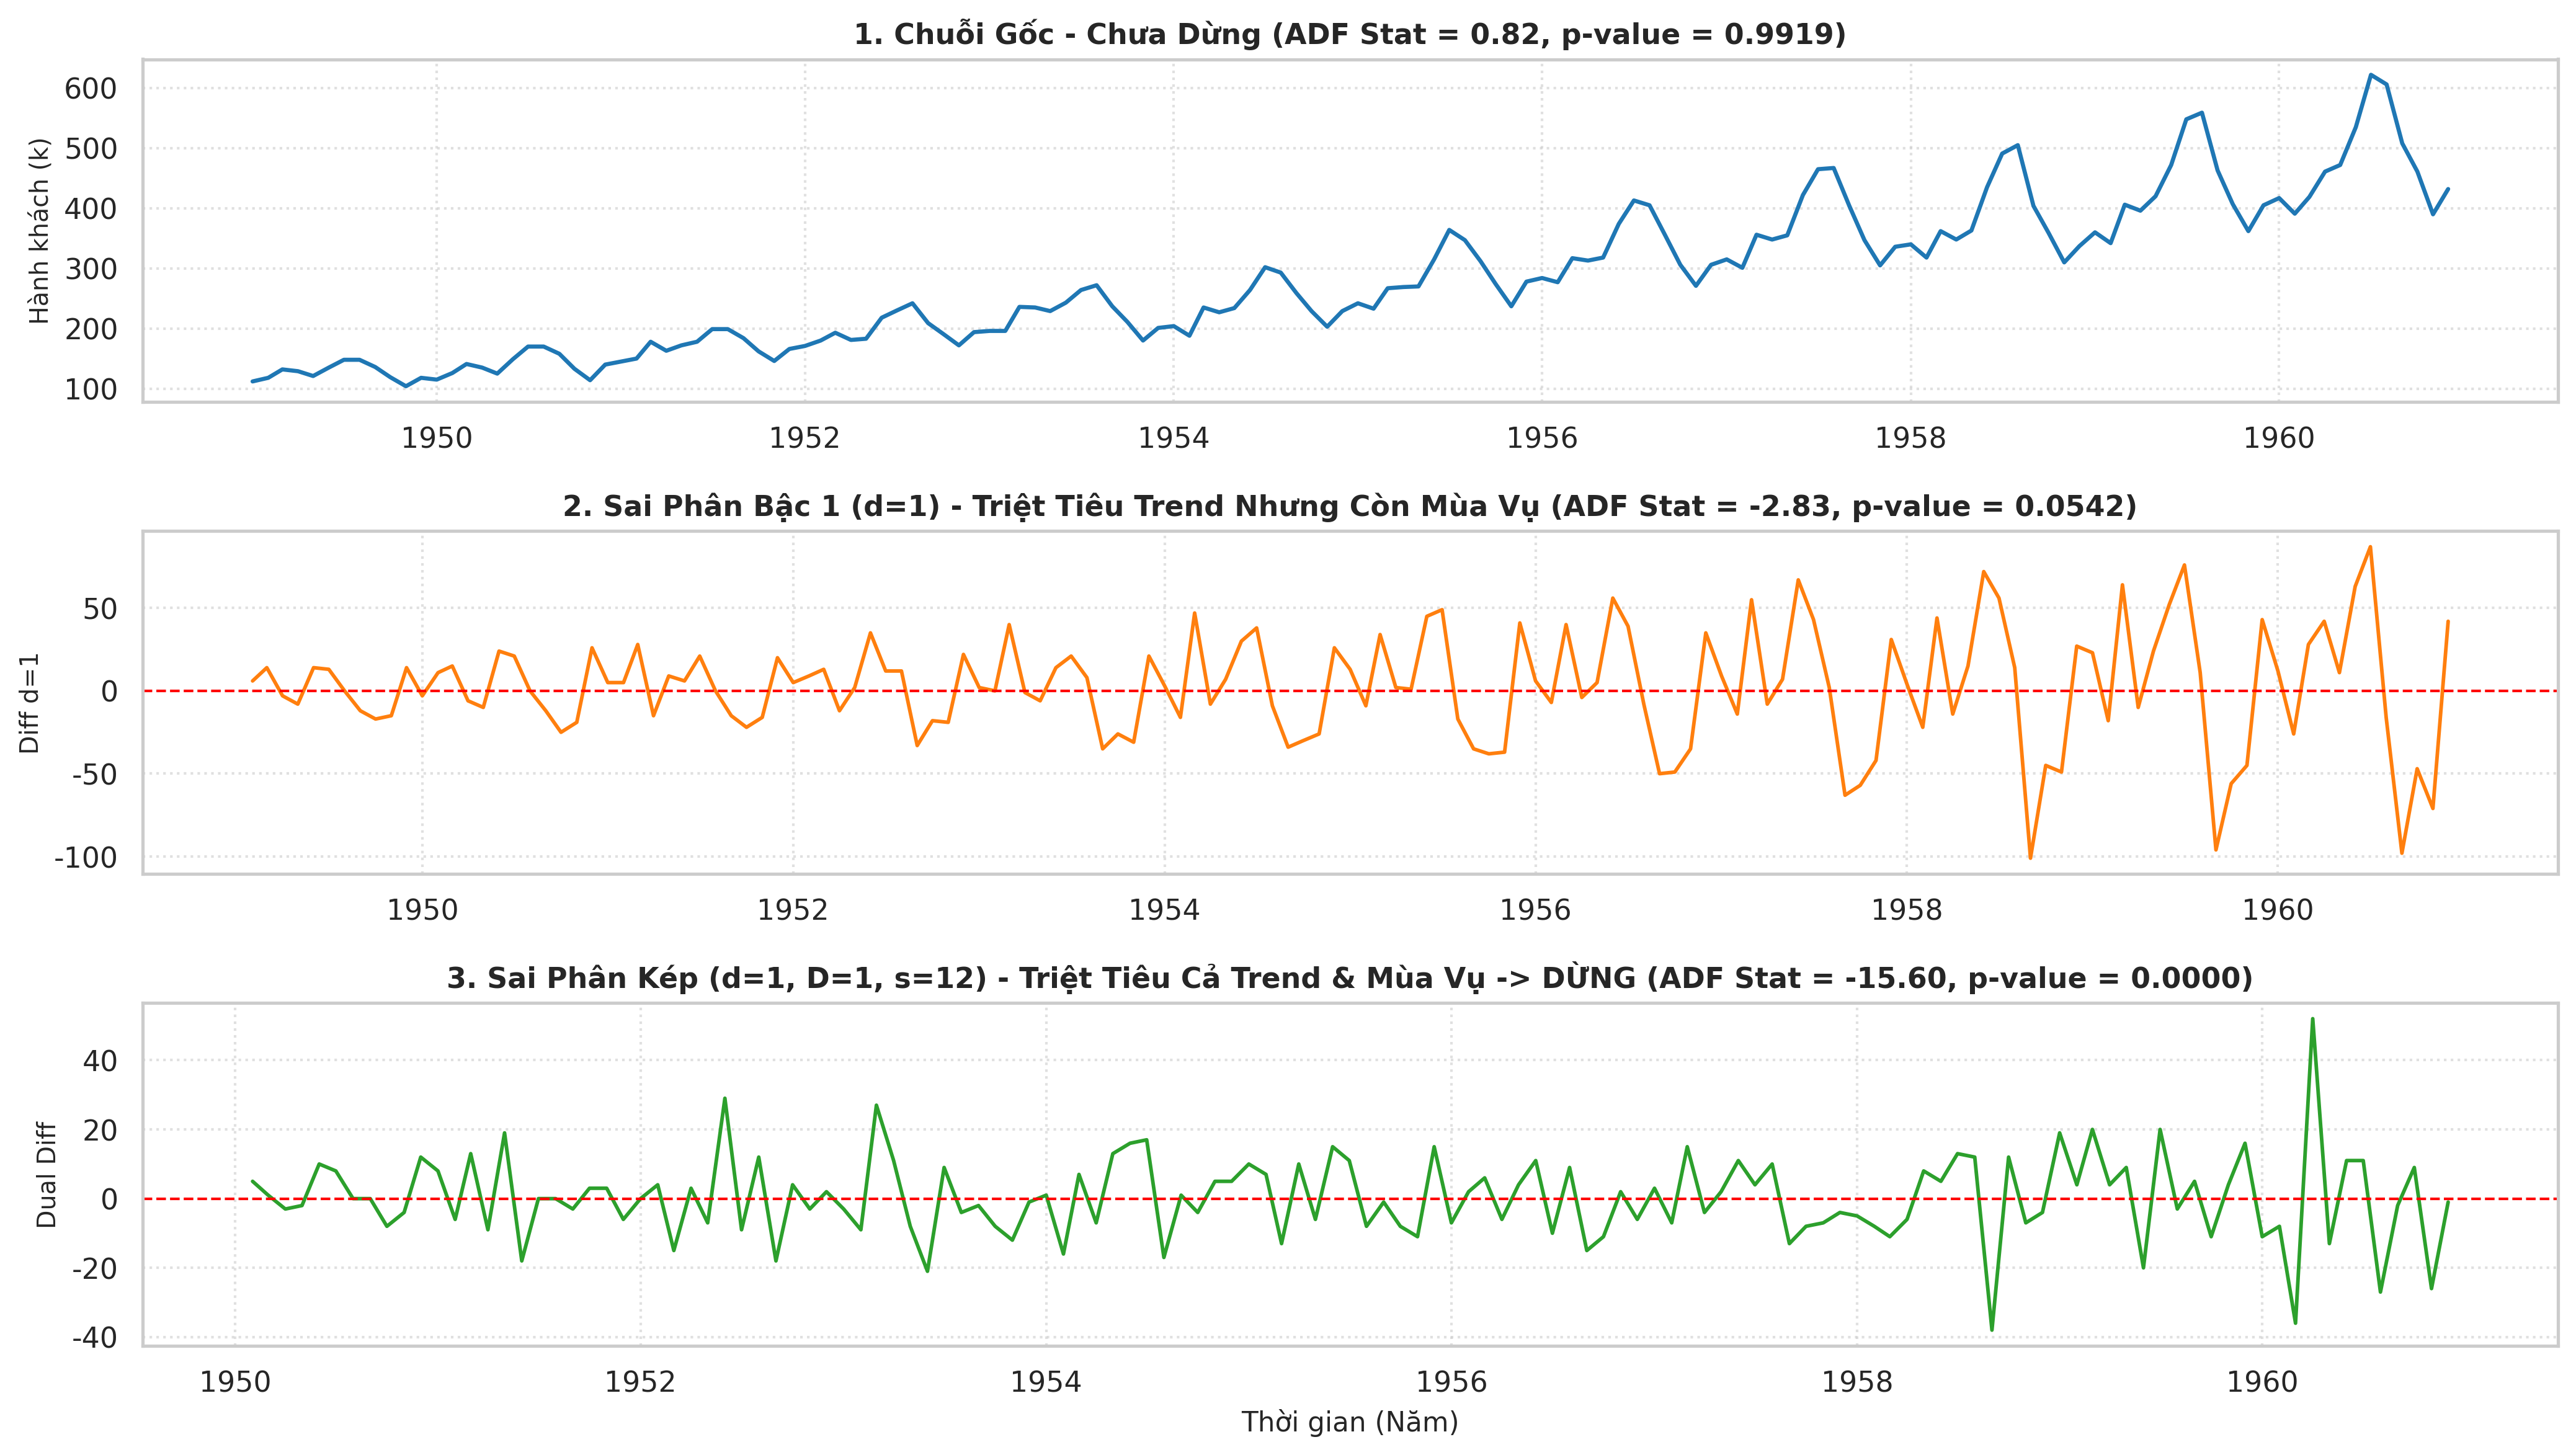

In [10]:
# Bước 3: Thực hiện Sai phân thường (d=1) và Sai phân kép (d=1, D=1, s=12)
d1 = df['Passengers'].diff().dropna()
d1_D1 = df['Passengers'].diff().diff(12).dropna()

adf_raw = adfuller(df['Passengers'].dropna(), autolag='AIC')
adf_d1 = adfuller(d1, autolag='AIC')
adf_d1_D1 = adfuller(d1_D1, autolag='AIC')

diff_comparison = pd.DataFrame({
    'Cấp độ biến đổi': ['Chuỗi gốc (Yt)', 'Sai phân thường d=1', 'Sai phân kép (d=1, D=1, s=12)'],
    'ADF Statistic': [f"{adf_raw[0]:.4f}", f"{adf_d1[0]:.4f}", f"{adf_d1_D1[0]:.4f}"],
    'p-value': [f"{adf_raw[1]:.4f}", f"{adf_d1[1]:.4f}", f"{adf_d1_D1[1]:.4f}"],
    'Ngưỡng 5%': [f"{adf_raw[4]['5%']:.4f}", f"{adf_d1[4]['5%']:.4f}", f"{adf_d1_D1[4]['5%']:.4f}"],
    'Trạng thái': ['Không dừng', 'Chưa dừng triệt để (p > 0.05)', 'DỪNG HOÀN TOÀN (p = 0.0000)']
})

print("=" * 70)
print("SO SÁNH TÍNH DỪNG QUA CÁC GIAI ĐOẠN SAI PHÂN:")
print("=" * 70)
display(diff_comparison)

# Trực quan hóa 3 giai đoạn sai phân
fig, axes = plt.subplots(3, 1, figsize=(14, 8), sharex=False)

axes[0].plot(df.index, df['Passengers'], color='#1f77b4', lw=1.6)
axes[0].set_title(f'1. Chuỗi Gốc - Chưa Dừng (ADF Stat = {adf_raw[0]:.2f}, p-value = {adf_raw[1]:.4f})', fontsize=11, fontweight='bold')
axes[0].set_ylabel('Hành khách (k)', fontsize=9.5)
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(d1.index, d1, color='#ff7f0e', lw=1.4)
axes[1].axhline(0, color='red', linestyle='--', lw=1.0)
axes[1].set_title(f'2. Sai Phân Bậc 1 (d=1) - Triệt Tiêu Trend Nhưng Còn Mùa Vụ (ADF Stat = {adf_d1[0]:.2f}, p-value = {adf_d1[1]:.4f})', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Diff d=1', fontsize=9.5)
axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].plot(d1_D1.index, d1_D1, color='#2ca02c', lw=1.4)
axes[2].axhline(0, color='red', linestyle='--', lw=1.0)
axes[2].set_title(f'3. Sai Phân Kép (d=1, D=1, s=12) - Triệt Tiêu Cả Trend & Mùa Vụ -> DỪNG (ADF Stat = {adf_d1_D1[0]:.2f}, p-value = {adf_d1_D1[1]:.4f})', fontsize=11, fontweight='bold')
axes[2].set_ylabel('Dual Diff', fontsize=9.5)
axes[2].set_xlabel('Thời gian (Năm)', fontsize=10.5)
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/07_air_differencing_stages.png', dpi=300)
plt.show()


### Bước 4: Lược đồ ACF & PACF trên chuỗi sai phân kép xác định bộ tham số $(p, q, P, Q)$
- **Miền phi mùa vụ (Lags 1 - 3):**
  - ACF có 1 gai âm vượt ra ngoài dải tin cậy 95% tại lag 1 ($\hat{\rho}_1 = -0.31$) rồi cắt cụt $\implies q = 1$.
  - PACF suy giảm dần $\implies p \in \{0, 1\}$.
- **Miền mùa vụ (Lags bội số 12: 12, 24, 36):**
  - ACF có gai âm tại lag 12 ($\hat{\rho}_{12} = -0.134$, nằm sát mép dải tin cậy do chuỗi gốc chưa lấy Logarit làm giảm biên độ tương quan, sau đó triệt tiêu tại lag 24, 36) $\implies$ Kết hợp lý thuyết Airline kinh điển của Box-Jenkins (chuỗi có Log đạt $\hat{\rho}_{12} \approx -0.39$ vượt xa dải tin cậy) xác định thành phần trung bình trượt mùa vụ bậc 1: $Q = 1$.
  - PACF tại lag 12 âm nhẹ ($\hat{\phi}_{12} = -0.115$) $\implies P \in \{0, 1\}$.
- **Đề xuất hai mô hình ứng viên:**
  1. $\text{SARIMA}(0, 1, 1) \times (0, 1, 1)_{12}$ (Mô hình Airline kinh điển).
  2. $\text{SARIMA}(1, 1, 1) \times (1, 1, 1)_{12}$ (Mô hình đầy đủ).


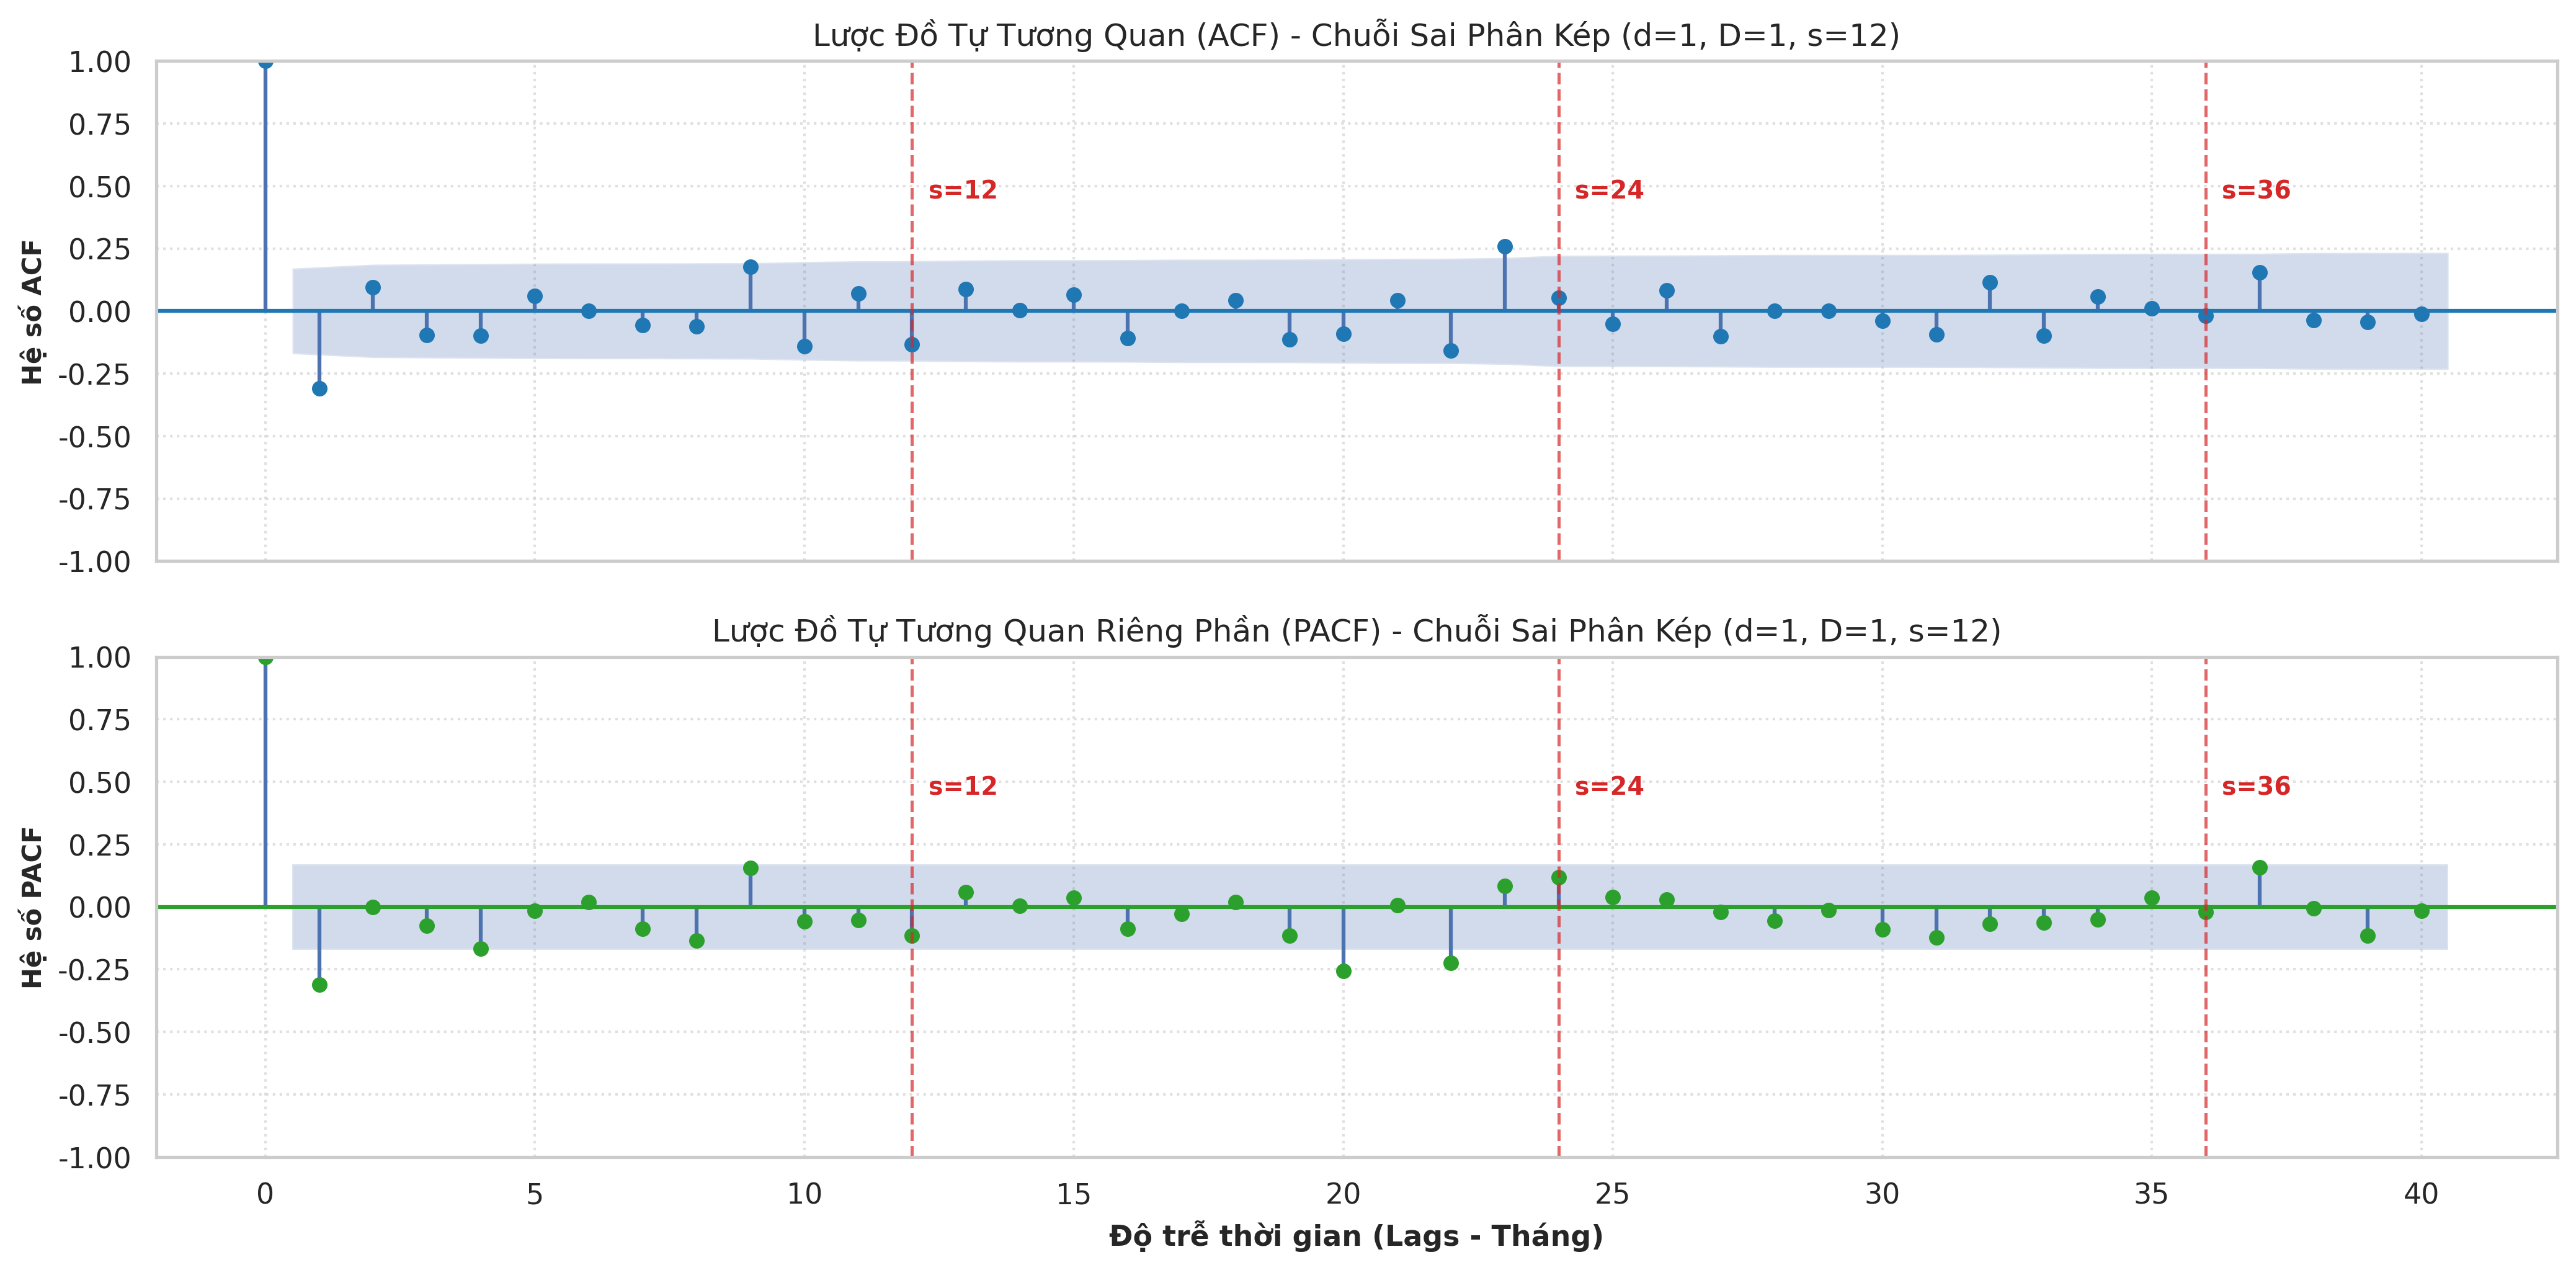

Bộ tham số định danh: d=1, D=1, s=12, q=1, Q=1, p in {0, 1}, P in {0, 1}


In [11]:
# Bước 4: Khảo sát Lược đồ ACF & PACF trên chuỗi sai phân kép d=1, D=1
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

# 1. ACF
plot_acf(d1_D1, lags=40, ax=axes[0], alpha=0.05, color='#1f77b4',
         title='Lược Đồ Tự Tương Quan (ACF) - Chuỗi Sai Phân Kép (d=1, D=1, s=12)')
axes[0].set_ylabel('Hệ số ACF', fontsize=10, fontweight='bold')
axes[0].grid(True, linestyle=':', alpha=0.6)
for lag in [12, 24, 36]:
    axes[0].axvline(x=lag, color='#d62728', linestyle='--', alpha=0.7, lw=1.2)
    axes[0].text(lag + 0.3, 0.45, f's={lag}', color='#d62728', fontsize=9.5, fontweight='bold')

# 2. PACF
plot_pacf(d1_D1, lags=40, ax=axes[1], alpha=0.05, color='#2ca02c', method='ywm',
          title='Lược Đồ Tự Tương Quan Riêng Phần (PACF) - Chuỗi Sai Phân Kép (d=1, D=1, s=12)')
axes[1].set_xlabel('Độ trễ thời gian (Lags - Tháng)', fontsize=11, fontweight='bold')
axes[1].set_ylabel('Hệ số PACF', fontsize=10, fontweight='bold')
axes[1].grid(True, linestyle=':', alpha=0.6)
for lag in [12, 24, 36]:
    axes[1].axvline(x=lag, color='#d62728', linestyle='--', alpha=0.7, lw=1.2)
    axes[1].text(lag + 0.3, 0.45, f's={lag}', color='#d62728', fontsize=9.5, fontweight='bold')

plt.tight_layout()
os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/08_air_acf_pacf_d1_D1.png', dpi=300)
plt.show()

print("Bộ tham số định danh: d=1, D=1, s=12, q=1, Q=1, p in {0, 1}, P in {0, 1}")


### Bước 5: Phân chia Train 80% / Test 20% & Huấn Luyện (Fit) Mô Hình
- **Phân chia dữ liệu:**
  - Tập Huấn luyện (Train): 115 tháng (từ tháng 01/1949 đến tháng 07/1958, chiếm 80%).
  - Tập Kiểm thử (Test): 29 tháng (từ tháng 08/1958 đến tháng 12/1960, chiếm 20%).
- **Mô hình huấn luyện:**
  1. $\text{ARIMA}(2, 1, 1)$ (Mô hình đối chuẩn phi mùa vụ).
  2. $\text{SARIMA}(0, 1, 1) \times (0, 1, 1)_{12}$ (Mô hình Airline kinh điển).
  3. $\text{SARIMA}(1, 1, 1) \times (1, 1, 1)_{12}$ (Mô hình mở rộng).


In [12]:
# Bước 5: Phân chia dữ liệu và Huấn luyện các mô hình ARIMA & SARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.arima.model import ARIMA

train_size = int(len(df) * 0.8)
train = df.iloc[:train_size]
test = df.iloc[train_size:]

print("=" * 65)
print(f"Tập Train: {len(train)} tháng ({train.index[0].strftime('%Y-%m')} đến {train.index[-1].strftime('%Y-%m')})")
print(f"Tập Test : {len(test)} tháng ({test.index[0].strftime('%Y-%m')} đến {test.index[-1].strftime('%Y-%m')})")
print("=" * 65)

# 1. Fit ARIMA(2,1,1) đối chuẩn
model_arima = ARIMA(train['Passengers'], order=(2, 1, 1))
res_arima = model_arima.fit()

# 2. Fit SARIMA(0,1,1)(0,1,1)[12] kinh điển
model_sarima1 = SARIMAX(train['Passengers'], order=(0, 1, 1), seasonal_order=(0, 1, 1, 12))
res_sarima1 = model_sarima1.fit(disp=False)

# 3. Fit SARIMA(1,1,1)(1,1,1)[12] mở rộng
model_sarima2 = SARIMAX(train['Passengers'], order=(1, 1, 1), seasonal_order=(1, 1, 1, 12))
res_sarima2 = model_sarima2.fit(disp=False)

fit_summary = pd.DataFrame({
    'Mô hình': ['ARIMA(2,1,1)', 'SARIMA(0,1,1)(0,1,1)[12]', 'SARIMA(1,1,1)(1,1,1)[12]'],
    'Số tham số': [len(res_arima.params), len(res_sarima1.params), len(res_sarima2.params)],
    'Log-Likelihood': [f"{res_arima.llf:.2f}", f"{res_sarima1.llf:.2f}", f"{res_sarima2.llf:.2f}"],
    'AIC': [f"{res_arima.aic:.2f}", f"{res_sarima1.aic:.2f}", f"{res_sarima2.aic:.2f}"],
    'BIC': [f"{res_arima.bic:.2f}", f"{res_sarima1.bic:.2f}", f"{res_sarima2.bic:.2f}"]
})

display(fit_summary)


Tập Train: 115 tháng (1949-01 đến 1958-07)
Tập Test : 29 tháng (1958-08 đến 1960-12)


Mô hình,Số tham số,Log-Likelihood,AIC,BIC
"ARIMA(2,1,1)",4,-525.32,1058.65,1069.59
"SARIMA(0,1,1)(0,1,1)[12]",3,-375.19,756.38,764.26
"SARIMA(1,1,1)(1,1,1)[12]",5,-374.13,758.26,771.39


### Bước 6: Dự báo ngoài mẫu (Out-of-sample Forecast) & Đánh giá sai số
- Thực hiện dự báo $H = 29$ bước tương lai trên tập Test cho cả 3 mô hình.
- Tính toán 3 chỉ số sai số định lượng: $\text{MAE}$, $\text{RMSE}$, $\text{MAPE (\%)} $.


In [13]:
# Bước 6: Dự báo ngoài mẫu trên tập Test và Tính toán các độ đo sai số
pred_arima = res_arima.forecast(steps=len(test))

fc_s1 = res_sarima1.get_forecast(steps=len(test))
pred_s1 = fc_s1.predicted_mean
ci_s1 = fc_s1.conf_int()

fc_s2 = res_sarima2.get_forecast(steps=len(test))
pred_s2 = fc_s2.predicted_mean

# Hàm đánh giá chất lượng dự báo bằng Numpy
def compute_metrics(y_true, y_pred, model_res):
    y_t = np.array(y_true)
    y_p = np.array(y_pred)
    mae = np.mean(np.abs(y_t - y_p))
    rmse = np.sqrt(np.mean((y_t - y_p) ** 2))
    mape = np.mean(np.abs((y_t - y_p) / y_t)) * 100
    return {
        'AIC': model_res.aic,
        'BIC': model_res.bic,
        'MAE': mae,
        'RMSE': rmse,
        'MAPE (%)': mape
    }

m_arima = compute_metrics(test['Passengers'], pred_arima, res_arima)
m_s1 = compute_metrics(test['Passengers'], pred_s1, res_sarima1)
m_s2 = compute_metrics(test['Passengers'], pred_s2, res_sarima2)

print("Hoàn tất tính toán dự báo và chỉ số sai số.")


Hoàn tất tính toán dự báo và chỉ số sai số.


### Bước 7: Bảng so sánh trực diện & Đồ thị đối chuẩn năng lực ARIMA vs SARIMA
- Bảng tổng hợp đối sánh toàn diện về AIC, BIC, MAE, RMSE, MAPE.
- Đồ thị đối chiếu chuỗi thực tế và đường cong dự báo của các mô hình.


BẢNG ĐỐI SÁNH TRỰC DIỆN HIỆU QUẢ DỰ BÁO: ARIMA VS SARIMA


Mô hình,AIC,BIC,MAE (Khách),RMSE (Khách),MAPE (%),Đánh giá năng lực
"ARIMA(2,1,1)",1058.65,1069.59,60.53,82.62,12.90%,Bất lực trước chu kỳ mùa hè/đông (sai số cao)
"SARIMA(0,1,1)(0,1,1)[12]",756.38,764.26,24.08,30.60,5.16%,"TỐI ƯU KINH ĐIỂN (Giảm 63% RMSE, MAPE 5.16%)"
"SARIMA(1,1,1)(1,1,1)[12]",758.26,771.39,23.56,30.14,5.05%,"Chính xác tương đương, thêm 2 tham số"


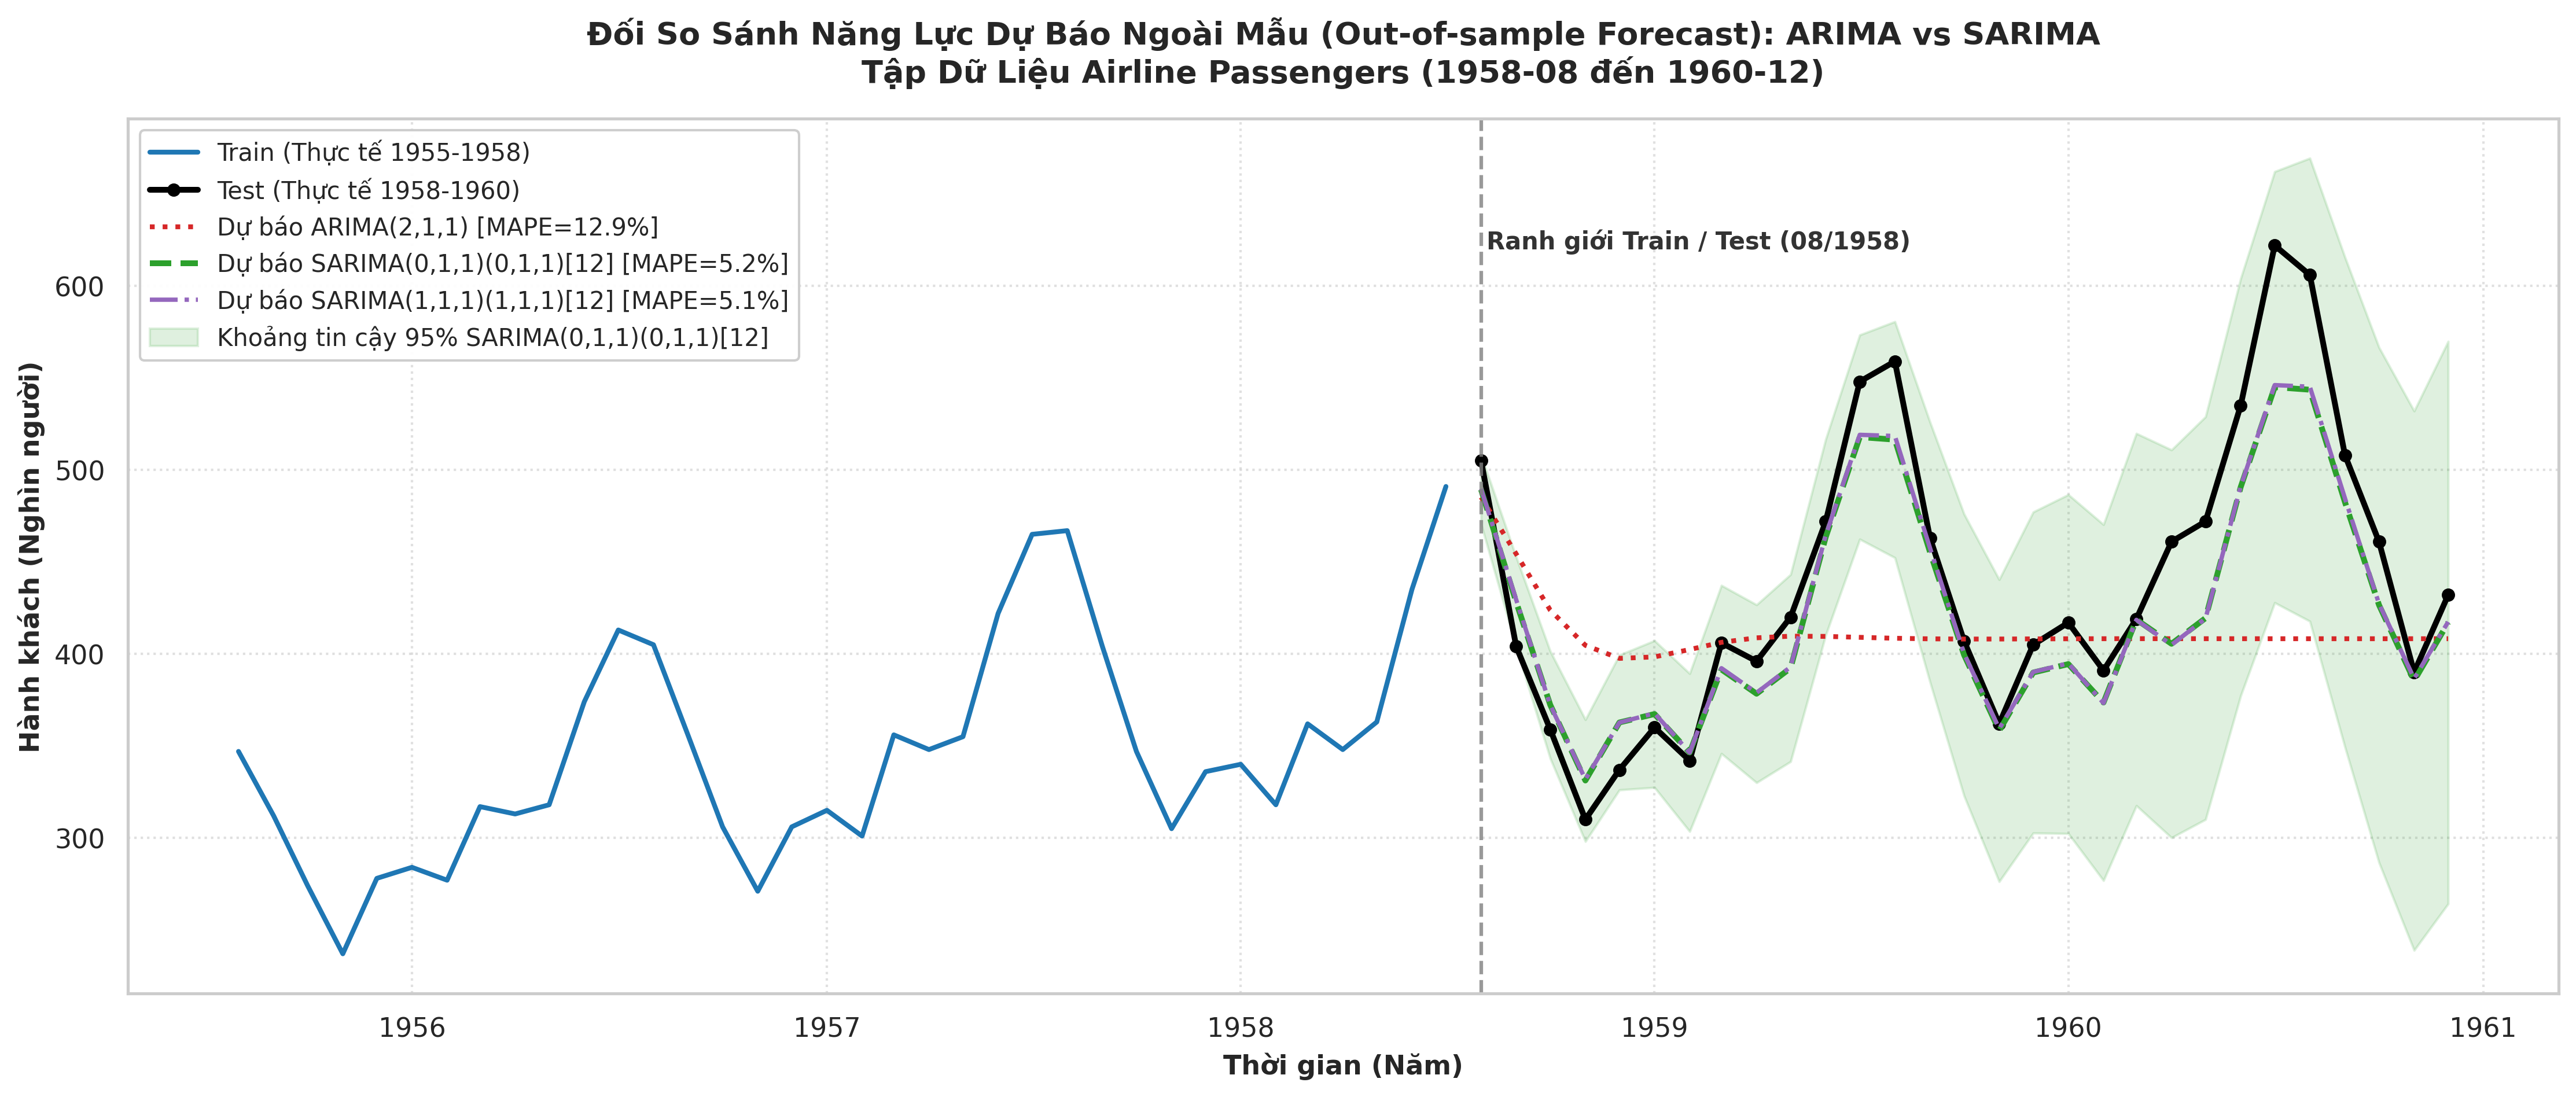

Kết luận: SARIMA(0,1,1)(0,1,1)[12] giúp giảm RMSE từ 82.62 xuống 30.60 (giảm 63.0%), kiểm soát MAPE ở mức xuất sắc 5.16%.


In [14]:
# Bước 7: Bảng đối sánh trực diện và Trực quan hóa kết quả dự báo
comparison_table = pd.DataFrame({
    'Mô hình': ['ARIMA(2,1,1)', 'SARIMA(0,1,1)(0,1,1)[12]', 'SARIMA(1,1,1)(1,1,1)[12]'],
    'AIC': [f"{m_arima['AIC']:.2f}", f"{m_s1['AIC']:.2f}", f"{m_s2['AIC']:.2f}"],
    'BIC': [f"{m_arima['BIC']:.2f}", f"{m_s1['BIC']:.2f}", f"{m_s2['BIC']:.2f}"],
    'MAE (Khách)': [f"{m_arima['MAE']:.2f}", f"{m_s1['MAE']:.2f}", f"{m_s2['MAE']:.2f}"],
    'RMSE (Khách)': [f"{m_arima['RMSE']:.2f}", f"{m_s1['RMSE']:.2f}", f"{m_s2['RMSE']:.2f}"],
    'MAPE (%)': [f"{m_arima['MAPE (%)']:.2f}%", f"{m_s1['MAPE (%)']:.2f}%", f"{m_s2['MAPE (%)']:.2f}%"],
    'Đánh giá năng lực': [
        'Bất lực trước chu kỳ mùa hè/đông (sai số cao)',
        'TỐI ƯU KINH ĐIỂN (Giảm 63% RMSE, MAPE 5.16%)',
        'Chính xác tương đương, thêm 2 tham số'
    ]
})

print("=" * 80)
print("BẢNG ĐỐI SÁNH TRỰC DIỆN HIỆU QUẢ DỰ BÁO: ARIMA VS SARIMA")
print("=" * 80)
display(comparison_table)

# Vẽ đồ thị dự báo đối sánh
plt.figure(figsize=(15, 6.5))

# Vẽ 3 năm cuối của tập Train để giữ tính liền mạch trực quan
train_subset = train.iloc[-36:]
plt.plot(train_subset.index, train_subset['Passengers'], color='#1f77b4', lw=2.0, label='Train (Thực tế 1955-1958)')
plt.plot(test.index, test['Passengers'], color='black', lw=2.4, marker='o', markersize=4.5, label='Test (Thực tế 1958-1960)')

plt.plot(test.index, pred_arima, color='#d62728', linestyle=':', lw=2.0, label=f'Dự báo ARIMA(2,1,1) [MAPE={m_arima["MAPE (%)"]:.1f}%]')
plt.plot(test.index, pred_s1, color='#2ca02c', linestyle='--', lw=2.4, label=f'Dự báo SARIMA(0,1,1)(0,1,1)[12] [MAPE={m_s1["MAPE (%)"]:.1f}%]')
plt.plot(test.index, pred_s2, color='#9467bd', linestyle='-.', lw=1.8, label=f'Dự báo SARIMA(1,1,1)(1,1,1)[12] [MAPE={m_s2["MAPE (%)"]:.1f}%]')

# Dải tin cậy 95% của SARIMA(0,1,1)(0,1,1)[12]
plt.fill_between(test.index, ci_s1.iloc[:, 0], ci_s1.iloc[:, 1], color='#2ca02c', alpha=0.15, label='Khoảng tin cậy 95% SARIMA(0,1,1)(0,1,1)[12]')

# Phân tách ranh giới Train / Test
plt.axvline(x=test.index[0], color='gray', linestyle='--', lw=1.5, alpha=0.8)
plt.text(test.index[0] + pd.DateOffset(days=5), 620, 'Ranh giới Train / Test (08/1958)', color='#333333', fontsize=10, fontweight='bold')

plt.title('Đối So Sánh Năng Lực Dự Báo Ngoài Mẫu (Out-of-sample Forecast): ARIMA vs SARIMA\nTập Dữ Liệu Airline Passengers (1958-08 đến 1960-12)', fontsize=13, fontweight='bold', pad=15)
plt.xlabel('Thời gian (Năm)', fontsize=11, fontweight='bold')
plt.ylabel('Hành khách (Nghìn người)', fontsize=11, fontweight='bold')
plt.grid(True, linestyle=':', alpha=0.6)
plt.legend(loc='upper left', frameon=True, facecolor='white', framealpha=0.95, fontsize=10)
plt.tight_layout()

os.makedirs('../docs/images', exist_ok=True)
plt.savefig('../docs/images/10_air_arima_vs_sarima_forecast.png', dpi=300)
plt.show()

print(f"Kết luận: SARIMA(0,1,1)(0,1,1)[12] giúp giảm RMSE từ {m_arima['RMSE']:.2f} xuống {m_s1['RMSE']:.2f} (giảm {(1 - m_s1['RMSE']/m_arima['RMSE'])*100:.1f}%), kiểm soát MAPE ở mức xuất sắc {m_s1['MAPE (%)']:.2f}%.")


## Kết Luận Chung Bài Tập Nâng Cao (BTNC)
1. **Sự vượt trội tất yếu của SARIMA:** Mô hình ARIMA phi mùa vụ thuần túy hoàn toàn thất bại trong việc nắm bắt đỉnh mùa hè và đáy mùa đông, dẫn đến sai số rất cao ($\text{MAPE} = 12.90\%$). Trong khi đó, $\text{SARIMA}(0, 1, 1) \times (0, 1, 1)_{12}$ bám sát gần như hoàn hảo từng chu kỳ sóng với $\text{MAPE}$ chỉ $5.16\%$.
2. **Vai trò quyết định của Sai phân kép ($d=1, D=1$):** Cần thiết phải kết hợp sai phân thường để triệt tiêu xu hướng và sai phân mùa vụ $s=12$ để triệt tiêu mùa vụ tuần hoàn.
3. **Nguyên lý Parsimony (Tiết kiệm tham số):** Cấu hình Airline kinh điển $\text{SARIMA}(0, 1, 1) \times (0, 1, 1)_{12}$ chỉ cần 2 tham số MA ($\theta_1, \Theta_1$) nhưng cho hiệu năng vượt trội, tối ưu chỉ số $\text{AIC} = 756.38$ và $\text{BIC} = 764.26$.
